# Лабораторная работа 2. Классификация. Нейронные сети

## Введение

Классификация является одной из основных задач машинного обучения и заключается в определении принадлежности объектов к заранее заданным классам на основе их характеристик. Для решения данной задачи применяются различные алгоритмы, отличающиеся принципами работы, требованиями к данным и качеством получаемых результатов. Выбор подходящего метода классификации и настройка его гиперпараметров оказывают существенное влияние на точность и обобщающую способность модели.

**Цель лабораторной работы** - изучение и практическое применение методов классификации данных, реализованных в библиотеке Scikit-Learn, а также исследование возможностей построения и обучения нейронных сетей с использованием TensorFlow и визуализации процесса обучения в TensorBoard.

Для достижения поставленной цели необходимо решить следующие задачи:

1. Выбрать и подготовить набор данных для классификации, провести предварительный анализ, обработку данных и разделение на обучающую и тестовую выборки.
2. Реализовать классификационные модели с использованием наивного Байесовского классификатора, дерева решений, линейного дискриминантного анализа, метода опорных векторов и метода ближайших соседей.
3. Оценить качество построенных моделей с использованием метрик Accuracy, Precision, Recall, F1-Score и AUC-ROC.
4. Исследовать влияние гиперпараметров на качество классификации и определить их оптимальные значения.
5. Разработать и обучить нейронную сеть с использованием библиотеки TensorFlow, исследовать влияние её архитектуры и параметров обучения на получаемые результаты.
6. Визуализировать процесс обучения нейронной сети с помощью TensorBoard.
7. Провести сравнительный анализ полученных результатов и определить наиболее эффективный метод классификации для выбранного набора данных.

## Описание датасета

Для лабораторной работы используется датасет Wine Quality из репозитория UCI Machine Learning Repository. Он содержит физико-химические характеристики португальских вин и экспертные оценки их качества.

Исходный датасет состоит из двух наборов: 1599 образцов красного вина и 4898 образцов белого вина.

*Признаки датасета*:

- Фиксированная кислотность - содержание нелетучих кислот.
- Летучая кислотность - содержание летучих кислот.
- Лимонная кислота - концентрация лимонной кислоты.
- Остаточный сахар - содержание сахара после брожения.
- Хлориды - содержание солей.
- Свободный диоксид серы - количество свободного SO₂.
- Общий диоксид серы - суммарное содержание SO₂.
- Плотность - плотность вина.
- pH - показатель кислотности.
- Сульфаты - содержание сульфатов.
- Алкоголь - процентное содержание спирта.

*Целевая переменная*: «Качество» - экспертная оценка вина по шкале от 0 до 10.

Для удобства импорты библиотек собраны в одной ячейке.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_curve, auc
)

Для исследования формируется объединённый набор данных с дополнительным признаком, обозначающим тип вина.

In [2]:
df_red = pd.read_csv('winequality-red.csv', sep=';')
df_white = pd.read_csv('winequality-white.csv', sep=';')

df_red.columns = [
    "Фиксированная кислотность",
    "Летучая кислотность",
    "Лимонная кислота",
    "Остаточный сахар",
    "Хлориды",
    "Свободный диоксид серы",
    "Общий диоксид серы",
    "Плотность",
    "pH",
    "Сульфаты",
    "Алкоголь",
    "Качество",
]

df_red["Тип"] = 1
df_white["Тип"] = 0

df_white.columns = df_red.columns

df = pd.concat([df_red, df_white], ignore_index=True)

display(df.head())

df.info()

display(df.describe())

print("Количество дубликатов:", df.duplicated().sum())

,Фиксированная кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный диоксид серы,Общий диоксид серы,Плотность,pH,Сульфаты,Алкоголь,Качество,Тип
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Фиксированная кислотность  6497 non-null   float64
 1   Летучая кислотность        6497 non-null   float64
 2   Лимонная кислота           6497 non-null   float64
 3   Остаточный сахар           6497 non-null   float64
 4   Хлориды                    6497 non-null   float64
 5   Свободный диоксид серы     6497 non-null   float64
 6   Общий диоксид серы         6497 non-null   float64
 7   Плотность                  6497 non-null   float64
 8   pH                         6497 non-null   float64
 9   Сульфаты                   6497 non-null   float64
 10  Алкоголь                   6497 non-null   float64
 11  Качество                   6497 non-null   int64  
 12  Тип                        6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


,Фиксированная кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный диоксид серы,Общий диоксид серы,Плотность,pH,Сульфаты,Алкоголь,Качество,Тип
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378,0.246114
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255,0.430779
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000,0.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000,0.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000,0.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000,0.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000,1.000000


Количество дубликатов: 1177


В результате объединения получен набор данных из 6497 наблюдений и 13 столбцов. Все признаки имеют числовой тип данных, пропущенные значения отсутствуют.

В ходе проверки обнаружено 1177 дублирующихся записей, которые необходимо обработать перед разделением данных на обучающую и тестовую выборки.

## Подготовка датасета к классификации

Для исключения полностью совпадающих записей и предотвращения их попадания одновременно в обучающую и тестовую выборки выполняется удаление дубликатов с последующим обновлением индексов.

In [3]:
df = df.drop_duplicates().reset_index(drop=True)

print("После удаления:", df.shape)

После удаления: (5320, 13)


После удаления 1177 дублирующихся записей размер набора данных сократился с 6497 до 5320 наблюдений. Количество столбцов осталось неизменным - 13.

Для оценки сбалансированности классов проводится анализ распределения целевой переменной «Качество». Подсчитывается количество образцов для каждой оценки качества и строится столбчатая диаграмма.

Качество
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


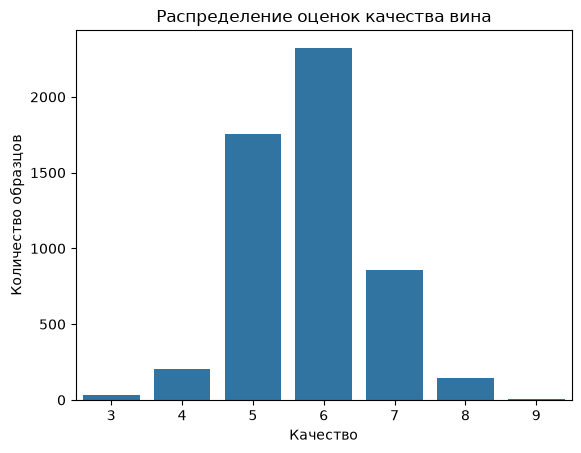

In [4]:
print(df["Качество"].value_counts().sort_index())

sns.countplot(data=df, x="Качество")
plt.title("Распределение оценок качества вина")
plt.xlabel("Качество")
plt.ylabel("Количество образцов")
plt.show()

Анализ показал, что классы распределены неравномерно. Наибольшее количество образцов имеет оценки 5 (1752 образца) и 6 (2323 образца), тогда как оценки 3 (30 образцов) и 9 (5 образцов) встречаются крайне редко.

Таким образом, в наборе данных наблюдается выраженный дисбаланс классов, который может отрицательно повлиять на качество классификации редких оценок. Для уменьшения дисбаланса и обеспечения более устойчивого обучения моделей целесообразно объединить исходные оценки в три категории: низкое, среднее и высокое качество.

Исходные оценки качества преобразуются в три условные категории: низкое качество (0–5), среднее качество (6) и высокое качество (7–10). Категории кодируются числами 0, 1 и 2 соответственно.

In [5]:
df["Класс качества"] = np.select(
    [
        df["Качество"] <= 5,
        df["Качество"] == 6,
        df["Качество"] >= 7
    ],
    [0, 1, 2]
)

В результате преобразования целевой переменной сформированы три класса качества вина:

- 0 - низкое качество: оценки от 0 до 5;
- 1 - среднее качество: оценка 6;
- 2 - высокое качество: оценки от 7 до 10.

Такое преобразование сокращает количество классов с семи до трёх, упрощая задачу классификации. При этом все наблюдения сохраняются, а исходная оценка качества остаётся в наборе данных для дальнейшего анализа.

Класс качества
0    1988
1    2323
2    1009
Name: count, dtype: int64


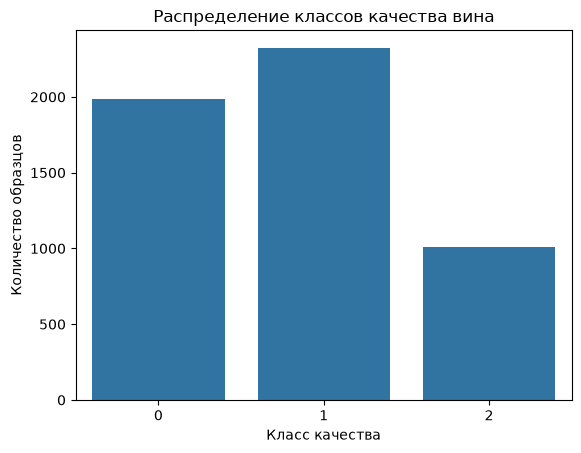

In [6]:
print(df["Класс качества"].value_counts().sort_index())

sns.countplot(data=df, x="Класс качества")
plt.title("Распределение классов качества вина")
plt.xlabel("Класс качества")
plt.ylabel("Количество образцов")
plt.show()

После объединения исходных оценок сформированы три класса качества вина:
- Класс 0 (низкое качество) - 1988 образцов;
- Класс 1 (среднее качество) - 2323 образца;
- Класс 2 (высокое качество) - 1009 образцов.

По сравнению с исходным распределением дисбаланс классов уменьшился, однако полностью не устранён. Наиболее многочисленным остаётся класс среднего качества, а наименее представленным - класс высокого качества.

Полученное распределение позволяет использовать все три класса при обучении и сравнении классификационных моделей. Для сохранения их пропорций при разделении данных будет применена стратификация.

Для выявления потенциальных выбросов строятся диаграммы размаха для каждого числового признака. Анализ проводится отдельно для красного и белого вина, поскольку распределения их физико-химических характеристик могут существенно различаться.

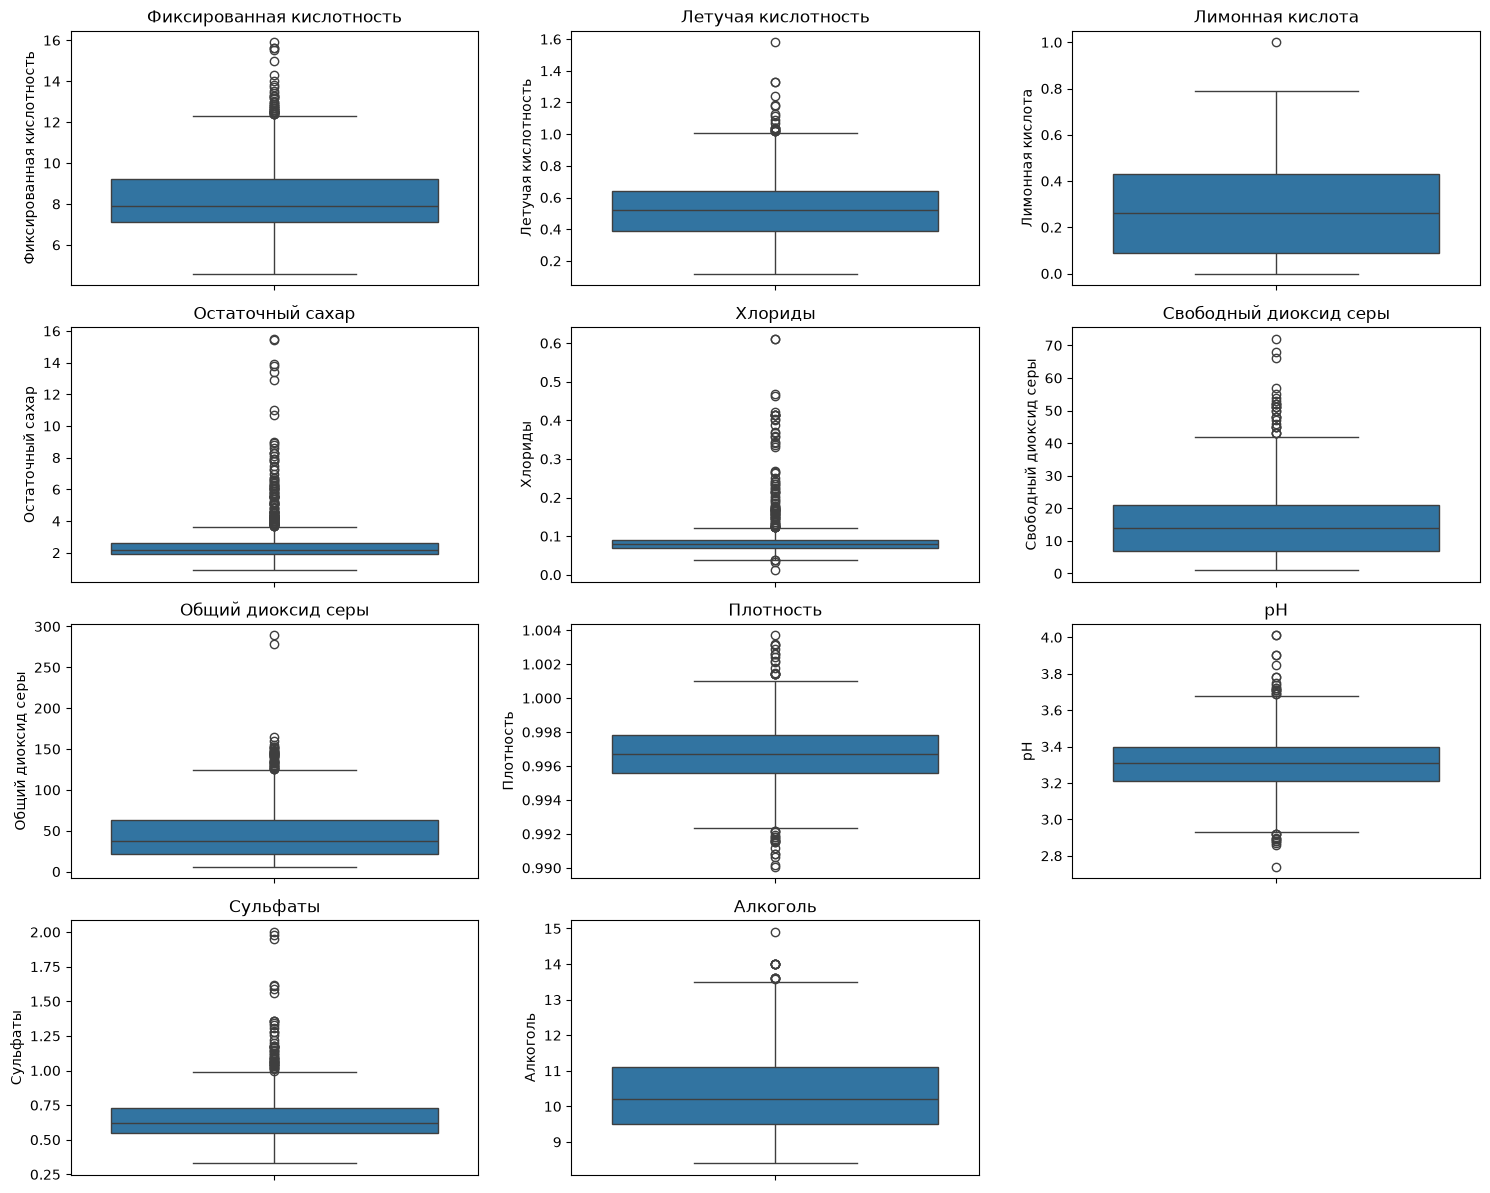

In [7]:
df_red = df[df["Тип"] == 1]
features = df_red.drop(columns=["Качество", "Тип", "Класс качества"])

plt.figure(figsize=(15, 12))

for i, col in enumerate(features.columns, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(y=df_red[col])
    plt.title(col)

plt.tight_layout()
plt.show()

На диаграммах размаха красного вина обнаружены потенциальные выбросы по большинству признаков. Наиболее заметные отклонения наблюдаются для остаточного сахара, хлоридов, сульфатов и отдельных показателей кислотности. При этом основная часть значений сосредоточена в относительно узких диапазонах.

Аналогичный анализ потенциальных выбросов проводится для белого вина.

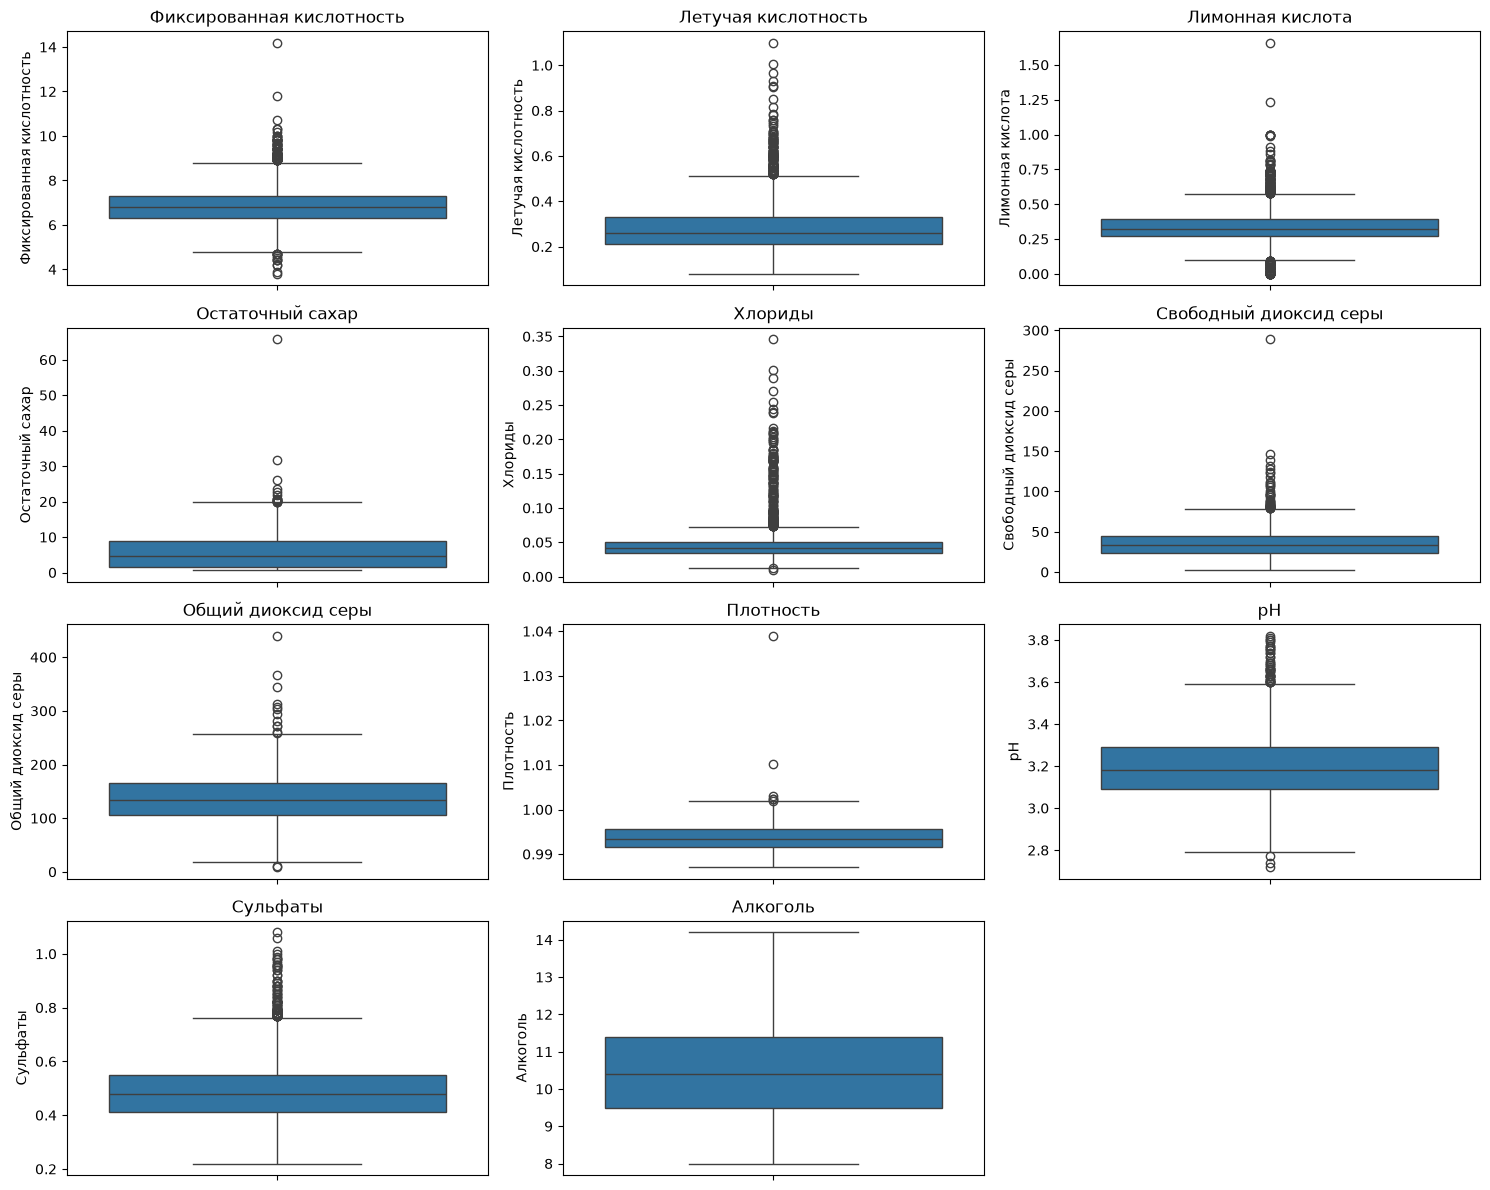

In [8]:
df_white = df[df["Тип"] == 0]
features = df_white.drop(columns=["Качество", "Тип", "Класс качества"])

plt.figure(figsize=(15, 12))

for i, col in enumerate(features.columns, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(y=df_white[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Анализ белого вина также выявил потенциальные выбросы, особенно для остаточного сахара, хлоридов, плотности и содержания диоксида серы. Распределения ряда признаков отличаются от красного вина: в частности, белые вина характеризуются более высоким содержанием остаточного сахара и общего диоксида серы.

Сравнение красного и белого вина показало различия в распределениях признаков. Для красного вина характерны более высокие значения фиксированной и летучей кислотности, хлоридов и сульфатов. Белое вино характеризуется более высоким содержанием остаточного сахара, свободного и общего диоксида серы. Эти различия подтверждают целесообразность сохранения признака «Тип» в объединённом наборе данных.

Анализ диаграмм размаха выявил потенциальные выбросы по ряду физико-химических характеристик. При этом среди рассмотренных значений не обнаружено очевидных ошибок, таких как отрицательные концентрации веществ или значения pH за пределами допустимой шкалы. Отдельные экстремальные показатели, например повышенное содержание остаточного сахара и диоксида серы, могут отражать особенности состава вина. Поскольку оснований считать эти значения ошибочными не выявлено, принято решение сохранить их без изменений.

Входные признаки отделяются от целевой переменной «Класс качества». Исходный столбец «Качество» исключается из признаков для предотвращения утечки целевой переменной.

Данные разделяются на обучающую (80%) и тестовую (20%) выборки с использованием стратификации для сохранения пропорций классов.

In [9]:
X = df.drop(columns=["Качество", "Класс качества"])
Y = df["Класс качества"]

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (4256, 12)
Тестовая выборка: (1064, 12)


В результате разбиения сформированы обучающая выборка из 4256 наблюдений и тестовая выборка из 1064 наблюдений. Каждое наблюдение содержит 12 входных признаков. Полученные выборки будут использоваться для обучения и оценки всех классификационных моделей.

### Стандартизированное представление набора данных

Поскольку числовые признаки имеют различные масштабы, выполняется стандартизация с помощью StandardScaler. Преобразование приводит признаки к нулевому среднему и единичному стандартному отклонению на обучающей выборке.

Параметры стандартизации вычисляются только на обучающих данных и затем применяются к тестовым. Бинарный признак «Тип» сохраняется без изменений.

In [10]:
numeric_features = X_train.columns.drop("Тип")

scaler = StandardScaler()

X_train_scaler = X_train.copy()
X_test_scaler = X_test.copy()

X_train_scaler[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaler[numeric_features] = scaler.transform(X_test[numeric_features])


display(X_train_scaler.head())

,Фиксированная кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный диоксид серы,Общий диоксид серы,Плотность,pH,Сульфаты,Алкоголь,Тип
683,1.184605,1.723140,-0.999159,-0.476384,0.751764,-0.280252,0.295922,1.223104,0.025545,0.051940,-0.805022,1
5013,-0.239693,-0.386210,0.352897,0.905599,-0.536040,-0.793656,-0.656926,0.087406,-1.092070,0.051940,0.459526,0
1913,-0.164730,1.312988,-1.472378,0.727278,1.025765,-0.394341,1.319353,0.893819,1.081070,-0.420979,-1.142235,0
3903,-1.589029,-0.093245,-0.323131,0.370638,-0.947041,0.803601,0.278277,-0.782848,0.832711,-0.961457,0.375223,0
2132,-0.539546,-0.503396,-0.323131,1.752621,-0.344239,2.229723,1.795777,0.725816,-0.346993,-0.691218,-0.467809,0


В результате стандартизации числовые признаки приведены к сопоставимому масштабу. Стандартизованные данные будут использоваться при обучении SVM, kNN, LDA и нейронной сети.

### Нормализованное представление набора данных

Для классификаторов MultinomialNB и ComplementNB, требующих неотрицательных входных значений, применяется масштабирование MinMaxScaler. Оно преобразует числовые признаки обучающей выборки в диапазон от 0 до 1.

Параметры преобразования определяются по обучающей выборке. Бинарный признак «Тип» остаётся без изменений.

In [11]:
minmax_scaler = MinMaxScaler(clip=True)
X_train_minmax = X_train.copy()
X_test_minmax = X_test.copy()

X_train_minmax[numeric_features] = minmax_scaler.fit_transform(X_train[numeric_features])
X_test_minmax[numeric_features] = minmax_scaler.transform(X_test[numeric_features])

display(X_train_minmax.head())

,Фиксированная кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный диоксид серы,Общий диоксид серы,Плотность,pH,Сульфаты,Алкоголь,Тип
683,0.413223,0.373333,0.102410,0.033794,0.124585,0.164948,0.343967,0.213418,0.395349,0.179775,0.231884,1
5013,0.256198,0.133333,0.222892,0.129032,0.046512,0.103093,0.194175,0.148255,0.255814,0.179775,0.449275,0
1913,0.264463,0.326667,0.060241,0.116743,0.141196,0.151203,0.504854,0.194525,0.527132,0.140449,0.173913,0
3903,0.107438,0.166667,0.162651,0.092166,0.021595,0.295533,0.341193,0.098323,0.496124,0.095506,0.434783,0
2132,0.223140,0.120000,0.162651,0.187404,0.058140,0.467354,0.579750,0.184885,0.348837,0.117978,0.289855,0


В результате нормализации числовые признаки обучающей выборки приведены к диапазону от 0 до 1. Сохранены относительные положения значений внутри каждого признака.

### Бинаризованное представление набора данных

Для применения классификатора BernoulliNB выполняется преобразование непрерывных признаков в бинарные значения. В качестве порога используется медиана каждого признака, рассчитанная по обучающей выборке.

Значения выше медианы кодируются единицей, остальные - нулём. Признак «Тип» уже является бинарным и не требует преобразования.

In [12]:
medians = X_train[numeric_features].median()

X_train_binary = X_train.copy()
X_test_binary = X_test.copy()

X_train_binary[numeric_features] = (X_train[numeric_features] > medians).astype(int)
X_test_binary[numeric_features] = (X_test[numeric_features] > medians).astype(int)

display(X_train_binary.head())

,Фиксированная кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный диоксид серы,Общий диоксид серы,Плотность,pH,Сульфаты,Алкоголь,Тип
683,1,1,0,1,1,0,1,1,1,1,0,1
5013,0,0,1,1,0,0,0,1,0,1,1,0
1913,0,1,0,1,1,0,1,1,1,0,0,0
3903,0,1,0,1,0,1,1,0,1,0,1,0
2132,0,0,0,1,0,1,1,1,0,0,0,0


В результате бинаризации все входные признаки принимают значения 0 или 1. Такое представление соответствует требованиям классификатора BernoulliNB.

В результате предварительной обработки сформированы четыре представления входных данных: исходное, стандартизованное, нормализованное и бинаризованное.

Каждое представление предназначено для определённых методов классификации с учётом их требований к входным признакам. Для всех моделей сохранены одинаковые обучающая и тестовая выборки, что обеспечивает сопоставимость результатов оценки качества классификации.

## Построение классификационных моделей

Для единообразной оценки моделей создаются вспомогательные функции. Первая функция строит матрицу ошибок: строки соответствуют истинным классам, столбцы - предсказанным.

In [13]:
def plot_confusion_matrix(y_true, y_pred, title):
    class_names = ["Низкое", "Среднее", "Высокое"]
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Greens",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"Матрица ошибок: {title}")
    plt.xlabel("Предсказанный класс")
    plt.ylabel("Истинный класс")
    plt.show()

Функция plot_class_metrics выводит Precision, Recall и F1-score для каждого класса на одном рисунке и в таблице. Precision характеризует правильность предсказаний класса, Recall - долю обнаруженных объектов этого класса, F1-score - сочетание этих двух показателей. Дополнительно рассчитываются макроусреднённые значения.

In [14]:
def plot_class_metrics(y_true, y_pred, model_name):
    class_names = ["Низкое", "Среднее", "Высокое"]

    metrics = {
        "Precision": precision_score(
            y_true, y_pred,
            labels=[0, 1, 2],
            average=None,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred,
            labels=[0, 1, 2],
            average=None,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred,
            labels=[0, 1, 2],
            average=None,
            zero_division=0
        )
    }

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, (metric_name, values) in zip(axes, metrics.items()):
        bars = ax.bar(
            class_names,
            values,
            color="steelblue"
        )

        ax.set_title(metric_name)
        ax.set_xlabel("Класс качества")
        ax.set_ylabel("Значение метрики")
        ax.set_ylim(0, 1)
        ax.bar_label(bars, fmt="%.3f", padding=3)
        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)

    fig.suptitle(f"Метрики по классам - {model_name}")
    plt.tight_layout()
    plt.show()

    metrics_df = pd.DataFrame(metrics, index=class_names)
    metrics_df.loc["Макроусреднение"] = metrics_df.mean(axis=0)
    metrics_df.index.name = "Класс качества"

    display(metrics_df.round(3))

    return metrics_df

Для оценки качества ранжирования создаётся функция построения ROC-кривых по принципу «один класс против остальных». Для каждого класса рассчитывается площадь под кривой, после чего определяется среднее значение AUC-macro. Используются вероятности классов или значения решающей функции модели.

In [15]:
def plot_roc(model, X_test_data, y_true, model_name):
    classes = np.array([0, 1, 2])

    y_binary = label_binarize(y_true, classes=classes)

    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_test_data)
    else:
        y_scores = model.decision_function(X_test_data)

    assert np.array_equal(model.classes_, classes)

    class_names = ["Низкое", "Среднее", "Высокое"]
    auc_values = []

    plt.figure(figsize=(7, 5))

    for i, class_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(
            y_binary[:, i],
            y_scores[:, i]
        )

        roc_auc = auc(fpr, tpr)
        auc_values.append(roc_auc)

        plt.plot(
            fpr,
            tpr,
            label=f"{class_name} (AUC = {roc_auc:.3f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        "k--",
        label="Случайное ранжирование"
    )

    plt.title(f"ROC-кривые - {model_name}")
    plt.xlabel("False Positive Rate (FPR)")
    plt.ylabel("True Positive Rate (TPR)")
    plt.xlim(0, 1)
    plt.ylim(0, 1.05)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    print(f"AUC-macro: {np.mean(auc_values):.3f}")

Подготовлены функции построения матрицы ошибок, диаграмм Precision, Recall и F1-score, а также ROC-кривых.

### Наивный Байесовский классификатор

#### GaussianNB

GaussianNB - гауссовский наивный Байесовский классификатор, предполагающий нормальное распределение значений каждого признака внутри класса и их условную независимость.

Модель обучается на исходных числовых признаках с использованием гиперпараметров по умолчанию.

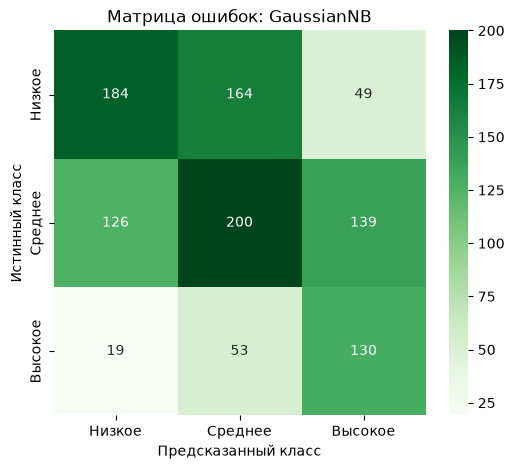

Accuracy: 0.4830827067669173


In [16]:
gaussian_nb = GaussianNB()

gaussian_nb.fit(X_train, Y_train)
Y_pred_gaussian = gaussian_nb.predict(X_test)

plot_confusion_matrix(Y_test, Y_pred_gaussian, "GaussianNB")

print("Accuracy:", accuracy_score(Y_test, Y_pred_gaussian))

GaussianNB правильно классифицировал 48,3% тестовых наблюдений. Матрица ошибок показывает, что модель часто смешивает классы качества: например, 164 образца низкого качества отнесены к среднему, а 139 образцов среднего качества - к высокому.

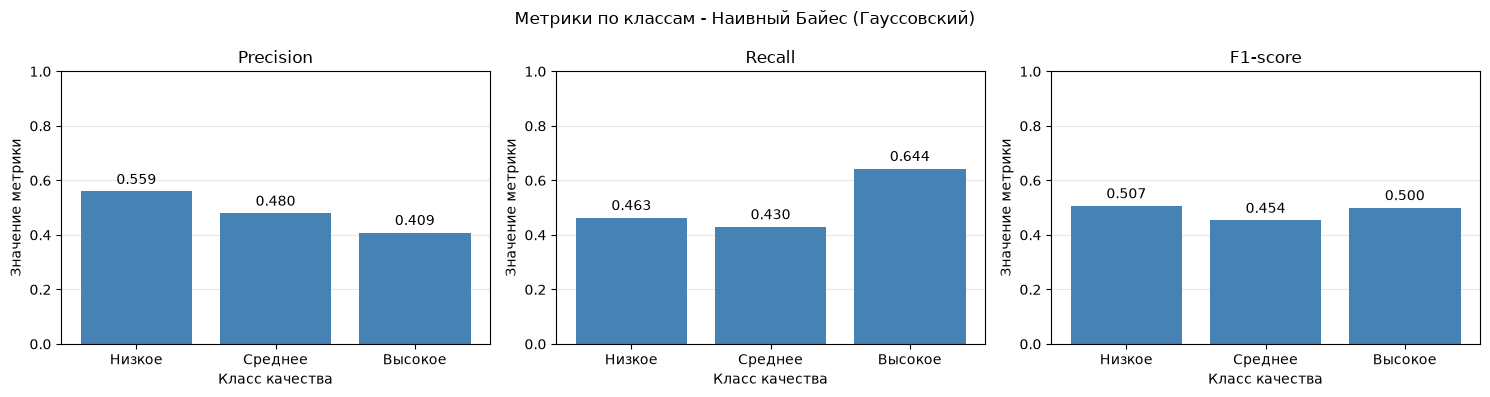

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.559,0.463,0.507
Среднее,0.480,0.430,0.454
Высокое,0.409,0.644,0.500
Макроусреднение,0.483,0.512,0.487


,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.559271,0.463476,0.506887
Среднее,0.479616,0.430108,0.453515
Высокое,0.408805,0.643564,0.500000
Макроусреднение,0.482564,0.512383,0.486801


In [17]:
plot_class_metrics(Y_test, Y_pred_gaussian, "Наивный Байес (Гауссовский)")

Высокий Recall высокого качества (0,644) сопровождается низким Precision (0,409). Модель обнаруживает большую часть объектов этого класса, но часто ошибочно относит к нему другие вина. Наименьший F1-score получен для среднего качества - 0,454.

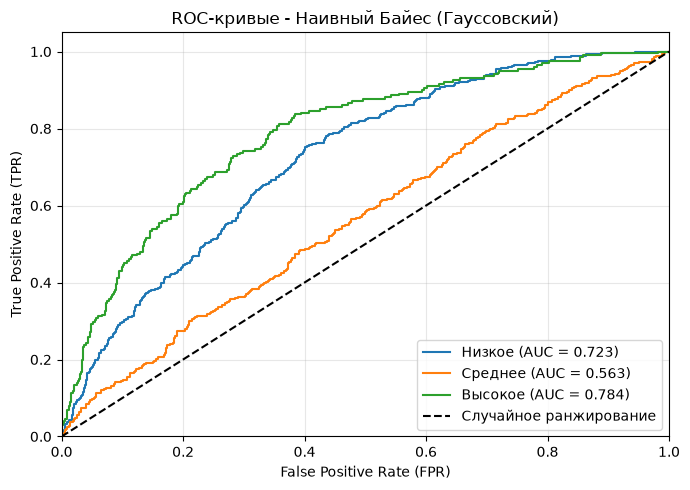

AUC-macro: 0.690


In [18]:
plot_roc(gaussian_nb, X_test, Y_test, "Наивный Байес (Гауссовский)")

AUC составил 0,723 для низкого, 0,563 для среднего и 0,784 для высокого качества. AUC-macro равен 0,690. Лучше всего модель ранжирует объекты по принадлежности к высокому качеству, а различение среднего качества лишь немного превосходит случайное ранжирование.

Полученные результаты используются как исходный уровень качества GaussianNB перед настройкой гиперпараметров.

#### MultinomialNB

MultinomialNB - разновидность наивного Байесовского классификатора, предназначенная преимущественно для неотрицательных счётных или частотных признаков.

В выбранном датасете признаки представляют собой физико-химические показатели вина, поэтому они не полностью соответствуют предположениям мультиномиальной модели. Классификатор применяется в рамках сравнительного эксперимента. Для обеспечения неотрицательности входных значений используется MinMaxScaler с параметром clip=True.

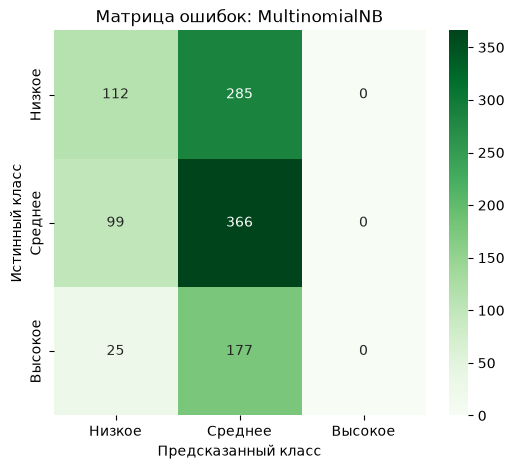

Accuracy: 0.4492481203007519


In [19]:
multinomial_nb = MultinomialNB()

multinomial_nb.fit(X_train_minmax, Y_train)
Y_pred_multinomial = multinomial_nb.predict(X_test_minmax)

plot_confusion_matrix(Y_test, Y_pred_multinomial, "MultinomialNB")

print("Accuracy:", accuracy_score(Y_test, Y_pred_multinomial))

Accuracy MultinomialNB составил 44,9%. Модель преимущественно предсказывает среднее качество и не относит ни одного тестового наблюдения к высокому качеству. Из 202 объектов высокого качества 177 отнесены к среднему и 25 - к низкому.

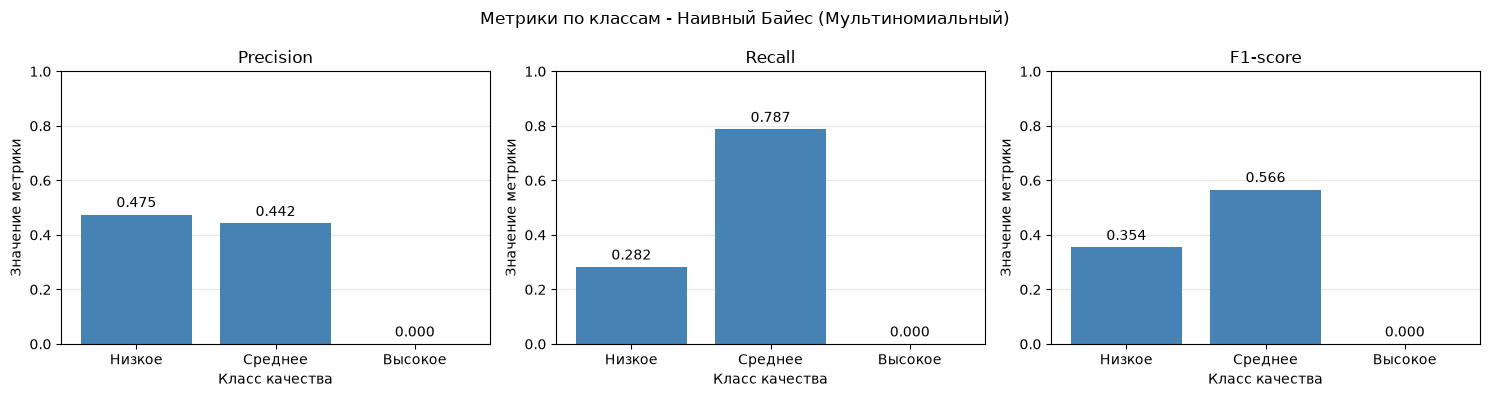

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.475,0.282,0.354
Среднее,0.442,0.787,0.566
Высокое,0.000,0.000,0.000
Макроусреднение,0.306,0.356,0.307


,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.474576,0.282116,0.353870
Среднее,0.442029,0.787097,0.566125
Высокое,0.000000,0.000000,0.000000
Макроусреднение,0.305535,0.356404,0.306665


In [20]:
plot_class_metrics(Y_test, Y_pred_multinomial, "Наивный Байес (Мультиномиальный)")

Модель не предсказывает высокое качество, поэтому Recall и F1-score этого класса равны 0.

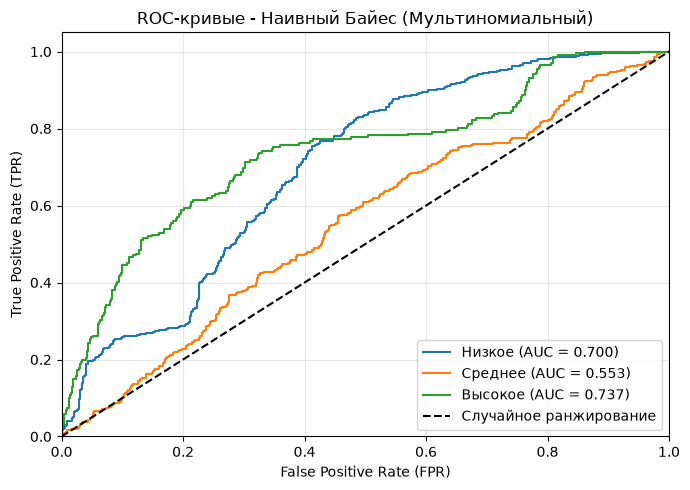

AUC-macro: 0.663


In [21]:
plot_roc(multinomial_nb, X_test_minmax, Y_test, "Наивный Байес (Мультиномиальный)")

AUC составил 0,700 для низкого, 0,553 для среднего и 0,737 для высокого качества. AUC-macro равен 0,663.

Ненулевой AUC высокого качества не противоречит нулевому Recall: вероятности позволяют ранжировать объекты по принадлежности к этому классу, но при выборе класса с максимальной вероятностью модель ни разу не выбирает высокое качество. При текущих параметрах MultinomialNB недостаточно эффективен для распознавания всех трёх классов.

#### ComplementNB

ComplementNB - модификация мультиномиального наивного Байеса, использующая статистику объектов, не принадлежащих рассматриваемому классу. Этот подход разработан для улучшения классификации, в частности при дисбалансе классов.

Как и MultinomialNB, данный классификатор предназначен преимущественно для счётных или частотных признаков. Его применение к физико-химическим показателям вина рассматривается как сравнительный эксперимент. Для обучения используются неотрицательные данные после Min-Max масштабирования.

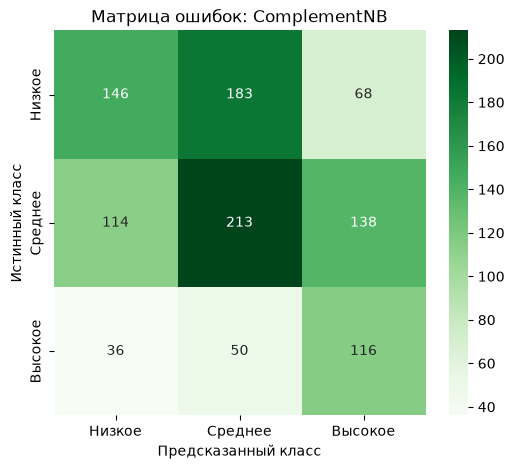

Accuracy: 0.44642857142857145


In [22]:
complement_nb = ComplementNB()

complement_nb.fit(X_train_minmax, Y_train)
Y_pred_complement = complement_nb.predict(X_test_minmax)

plot_confusion_matrix(Y_test, Y_pred_complement, "ComplementNB")

print("Accuracy:", accuracy_score(Y_test, Y_pred_complement))

Accuracy ComplementNB составил 44,6%. В отличие от MultinomialNB, модель предсказывает все три класса и правильно обнаруживает 116 объектов высокого качества. При этом 138 объектов среднего качества ошибочно отнесены к высокому.

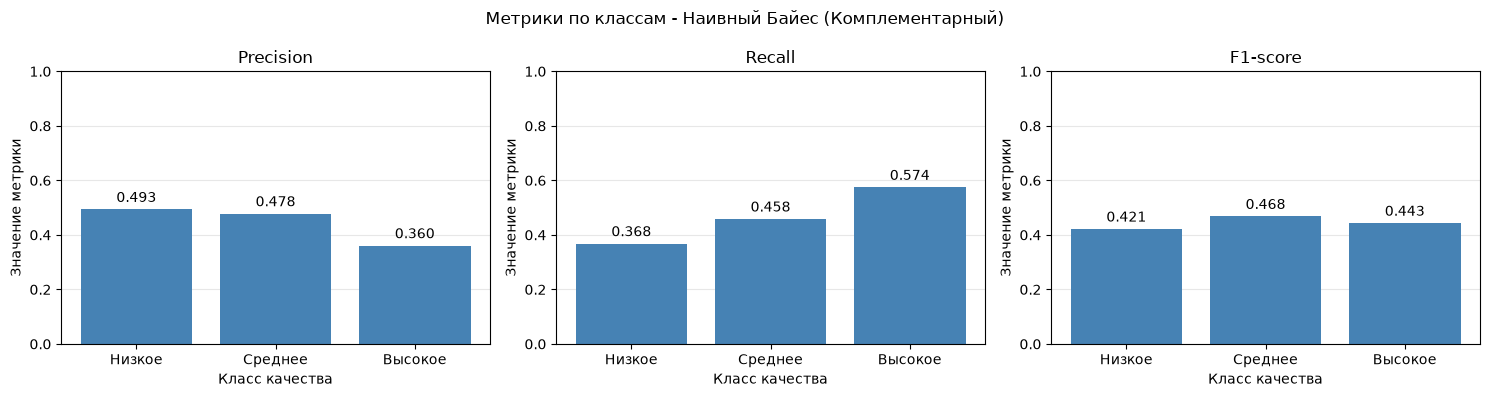

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.493,0.368,0.421
Среднее,0.478,0.458,0.468
Высокое,0.360,0.574,0.443
Макроусреднение,0.444,0.467,0.444


,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.493243,0.367758,0.421356
Среднее,0.477578,0.458065,0.467618
Высокое,0.360248,0.574257,0.442748
Макроусреднение,0.443690,0.466693,0.443908


In [23]:
plot_class_metrics(Y_test, Y_pred_complement, "Наивный Байес (Комплементарный)")

Модель распознаёт все три класса, но предсказания высокого качества наименее надёжны: Precision равен 0,360 при Recall 0,574.

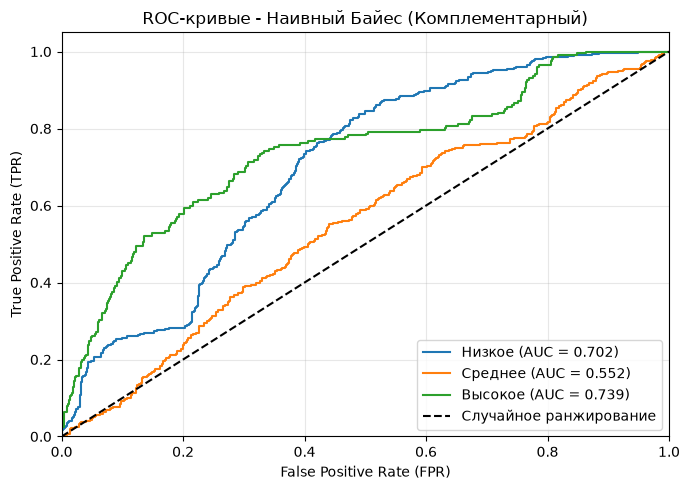

AUC-macro: 0.664


In [24]:
plot_roc(complement_nb, X_test_minmax, Y_test, "Наивный Байес (Комплементарный)")

AUC составил 0,702 для низкого, 0,552 для среднего и 0,739 для высокого качества. AUC-macro равен 0,664. По качеству ранжирования ComplementNB близок к MultinomialNB, но при выборе итогового класса обеспечивает более высокий F1-macro и распознаёт все три категории качества.

#### BernoulliNB

BernoulliNB - разновидность наивного Байесовского классификатора, предназначенная для бинарных признаков. Для обучения используются данные, предварительно преобразованные в значения 0 и 1 относительно медиан обучающей выборки.

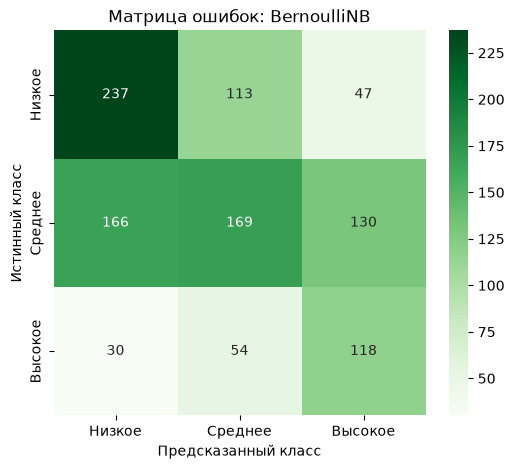

Accuracy: 0.4924812030075188


In [25]:
bernoulli_nb = BernoulliNB()

bernoulli_nb.fit(X_train_binary, Y_train)
Y_pred_bernoulli = bernoulli_nb.predict(X_test_binary)

plot_confusion_matrix(Y_test, Y_pred_bernoulli, "BernoulliNB")

print("Accuracy:", accuracy_score(Y_test, Y_pred_bernoulli))

Accuracy BernoulliNB составил 49,2%. Модель правильно классифицировала 237 объектов низкого, 169 объектов среднего и 118 объектов высокого качества. Большая часть объектов среднего качества отнесена к другим категориям.

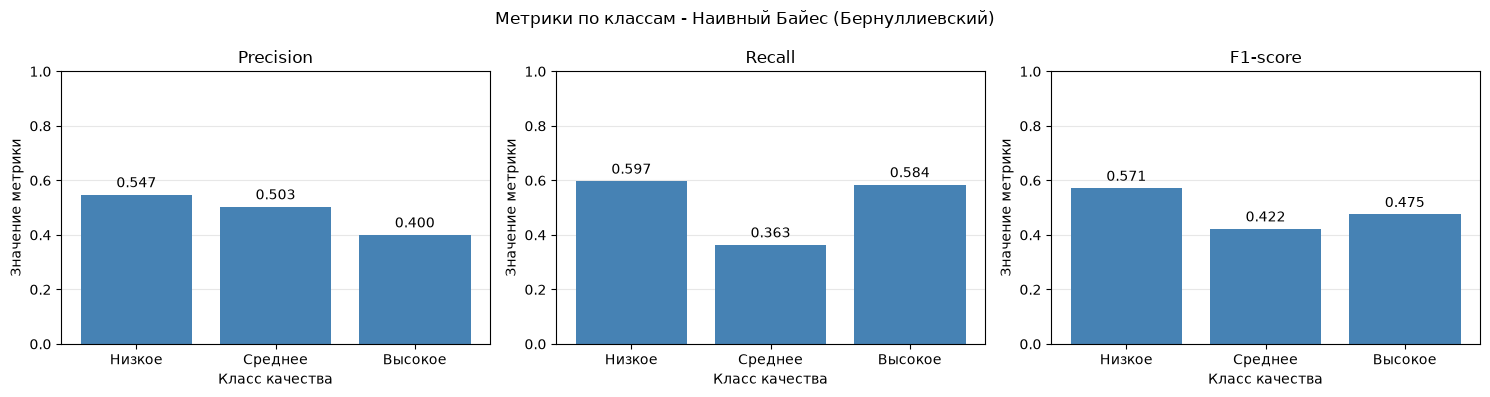

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.547,0.597,0.571
Среднее,0.503,0.363,0.422
Высокое,0.400,0.584,0.475
Макроусреднение,0.483,0.515,0.489


,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.547344,0.596977,0.571084
Среднее,0.502976,0.363441,0.421973
Высокое,0.400000,0.584158,0.474849
Макроусреднение,0.483440,0.514859,0.489302


In [26]:
plot_class_metrics(Y_test, Y_pred_bernoulli, "Наивный Байес (Бернуллиевский)")

Лучше всего распознаётся низкое качество по F1-score (0,571). Основная трудность - среднее качество, для которого Recall составляет 0,363.

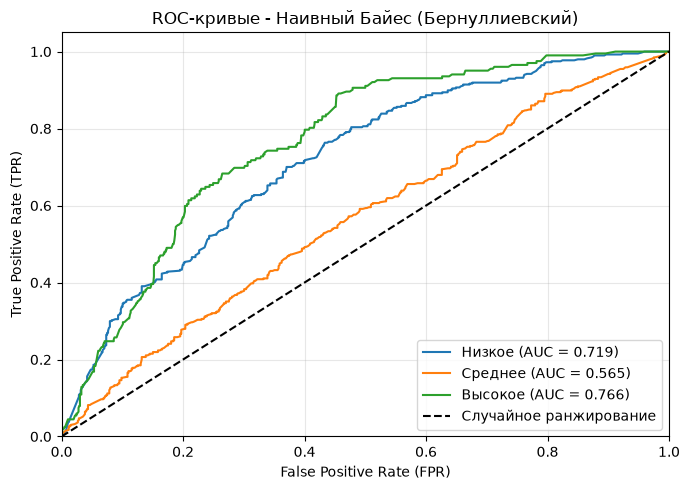

AUC-macro: 0.683


In [27]:
plot_roc(bernoulli_nb, X_test_binary, Y_test, "Наивный Байес (Бернуллиевский)")

AUC составил 0,719 для низкого, 0,565 для среднего и 0,766 для высокого качества. AUC-macro равен 0,683. Модель лучше различает низкое и высокое качество, тогда как ранжирование объектов среднего качества остаётся близким к случайному.

### Сравнение моделей наивного Байеса


Среди рассмотренных вариантов наивного Байеса наибольшие Accuracy и F1-macro получены у BernoulliNB: 0,492 и 0,489 соответственно. Однако его преимущество над GaussianNB по F1-macro невелико: у GaussianNB показатель равен 0,487. Наибольший AUC-macro получен у GaussianNB - 0,690.

MultinomialNB показал наименьший F1-macro - 0,307 - и не предсказал ни одного объекта высокого качества. ComplementNB распознаёт все три класса, но уступает GaussianNB и BernoulliNB по F1-macro.

При текущих параметрах BernoulliNB и GaussianNB являются наиболее успешными вариантами наивного Байеса для выбранного представления данных.

### Деревья решений (Decision Tree)

Decision Tree - алгоритм классификации, основанный на последовательном разделении данных по значениям признаков. На каждом этапе выбираются признак и порог, позволяющие разделить наблюдения на более однородные группы.

Для обучения используется DecisionTreeClassifier из библиотеки Scikit-Learn с гиперпараметрами по умолчанию. Масштабирование признаков не требуется, поэтому применяются исходные обучающая и тестовая выборки.

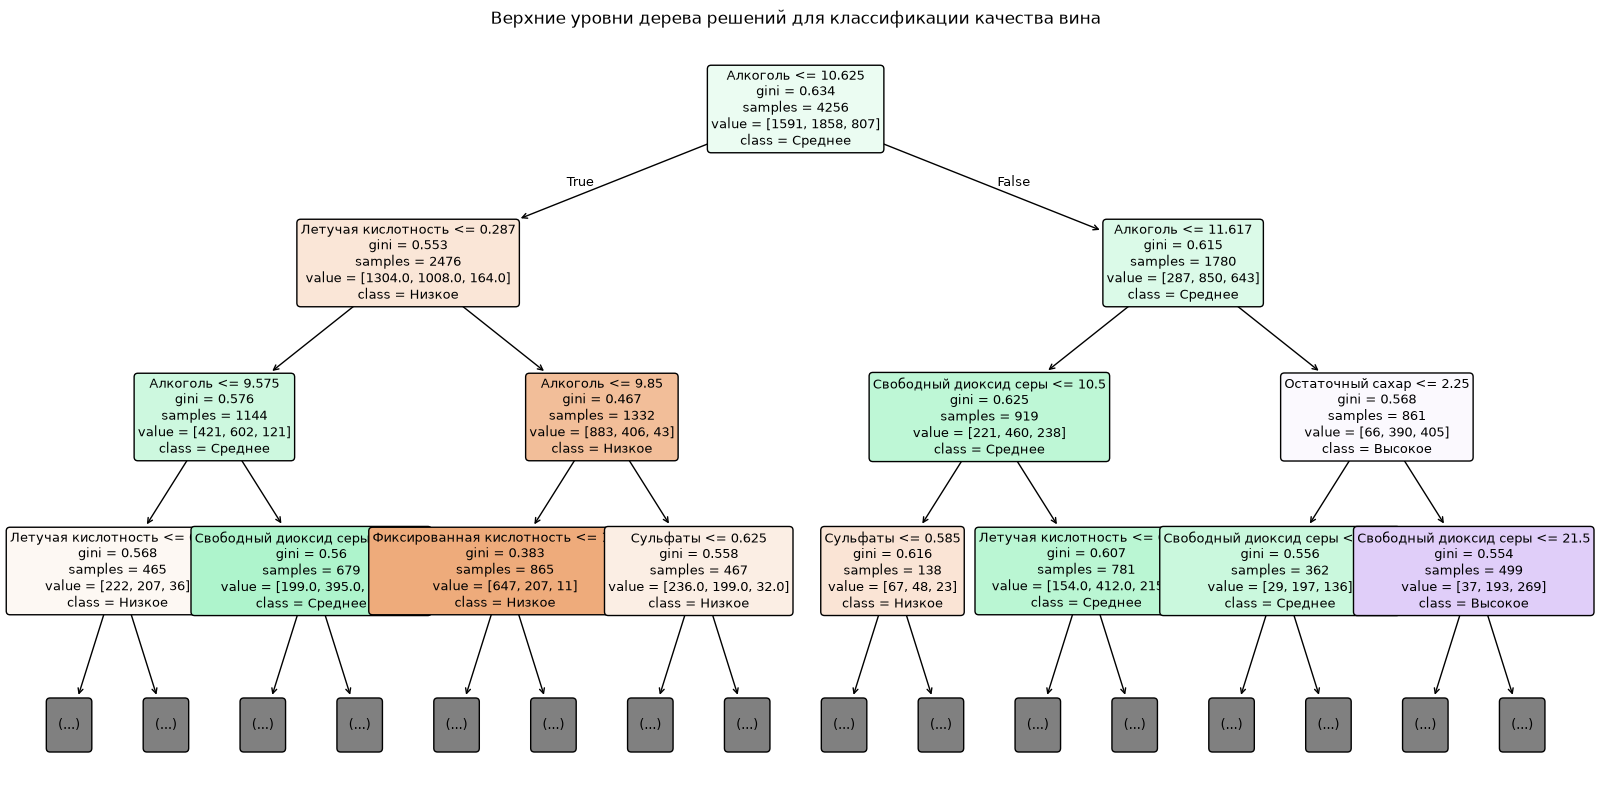

In [28]:
decision_tree = DecisionTreeClassifier(random_state=42)

decision_tree.fit(X_train, Y_train)
Y_pred_tree = decision_tree.predict(X_test)

plt.figure(figsize=(20, 10))

plot_tree(
    decision_tree,
    feature_names=X_train.columns,
    class_names=["Низкое", "Среднее", "Высокое"],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3
)

plt.title("Верхние уровни дерева решений для классификации качества вина")
plt.show()

Модель дерева решений обучена на исходных признаках. На рисунке показаны только верхние уровни дерева: параметр max_depth=3 в функции plot_tree ограничивает отображение, а не глубину обученной модели. Первое разделение выполняется по содержанию алкоголя с порогом около 10,625.

Для оценки предсказаний на тестовой выборке строится матрица ошибок и рассчитывается Accuracy.

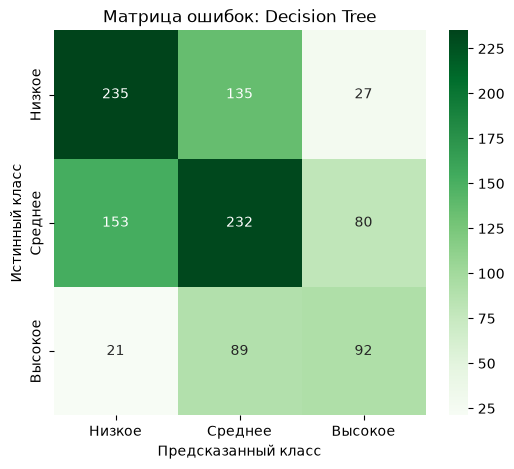

Accuracy: 0.525375939849624


In [29]:
plot_confusion_matrix(Y_test, Y_pred_tree, "Decision Tree")
print("Accuracy:", accuracy_score(Y_test, Y_pred_tree))

Accuracy дерева решений составил 52,5%. Правильно классифицированы 235 объектов низкого, 232 объекта среднего и 92 объекта высокого качества. Частые ошибки наблюдаются между низким и средним качеством, а также при отнесении высокого качества к среднему.

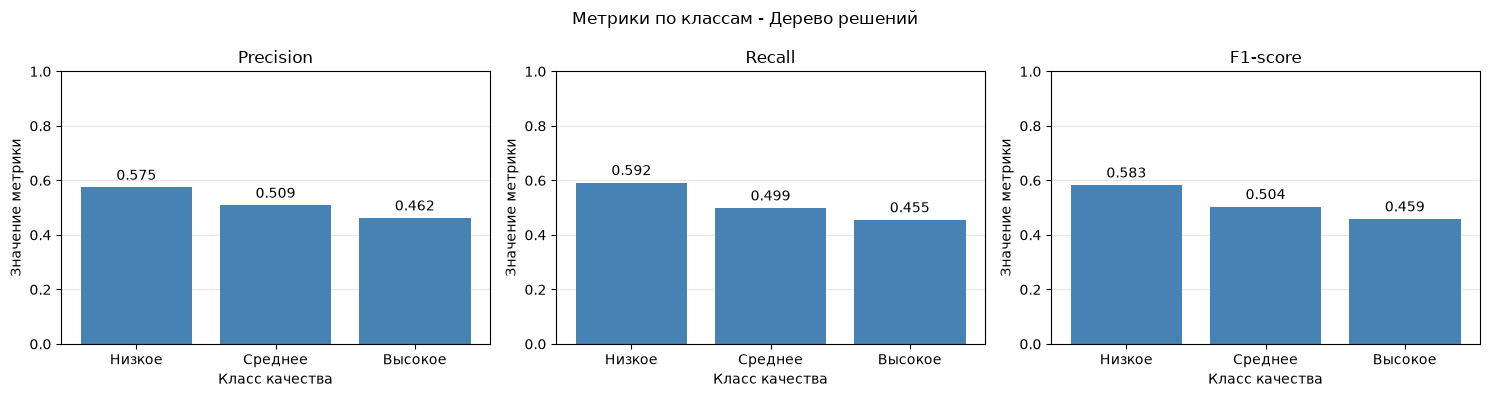

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.575,0.592,0.583
Среднее,0.509,0.499,0.504
Высокое,0.462,0.455,0.459
Макроусреднение,0.515,0.515,0.515


,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.574572,0.591940,0.583127
Среднее,0.508772,0.498925,0.503800
Высокое,0.462312,0.455446,0.458853
Макроусреднение,0.515219,0.515437,0.515260


In [30]:
plot_class_metrics(Y_test, Y_pred_tree, "Дерево решений")

Наибольший F1-score получен для низкого качества (0,583), наименьший - для высокого (0,459). Модель обнаруживает менее половины объектов высокого качества.

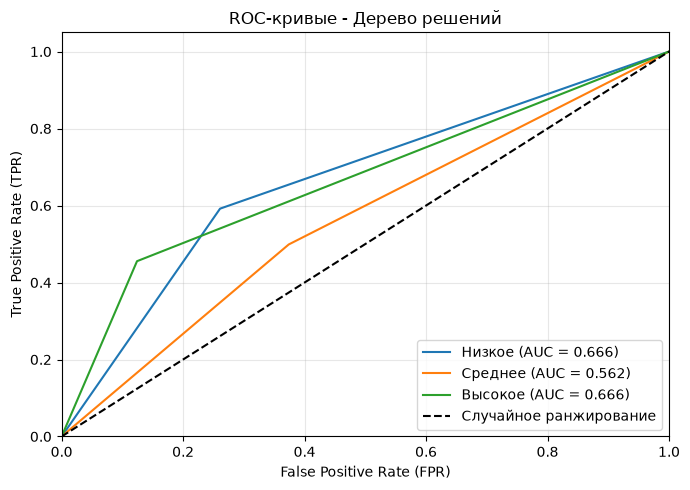

AUC-macro: 0.631


In [31]:
plot_roc(decision_tree, X_test, Y_test, "Дерево решений")

AUC составил 0,666 для низкого, 0,562 для среднего и 0,666 для высокого качества. AUC-macro равен 0,631. Несмотря на более высокий F1-macro по сравнению с наивным Байесом, дерево имеет более низкое качество ранжирования.

### Линейный дискриминантный анализ (LDA)

Linear Discriminant Analysis - метод классификации, основанный на построении линейных границ между классами. Алгоритм использует статистические характеристики распределений признаков, предполагая их многомерную нормальность внутри классов и равенство ковариационных матриц.

Для обучения используется LinearDiscriminantAnalysis из библиотеки Scikit-Learn с гиперпараметрами по умолчанию. Модель обучается на предварительно стандартизованных данных.

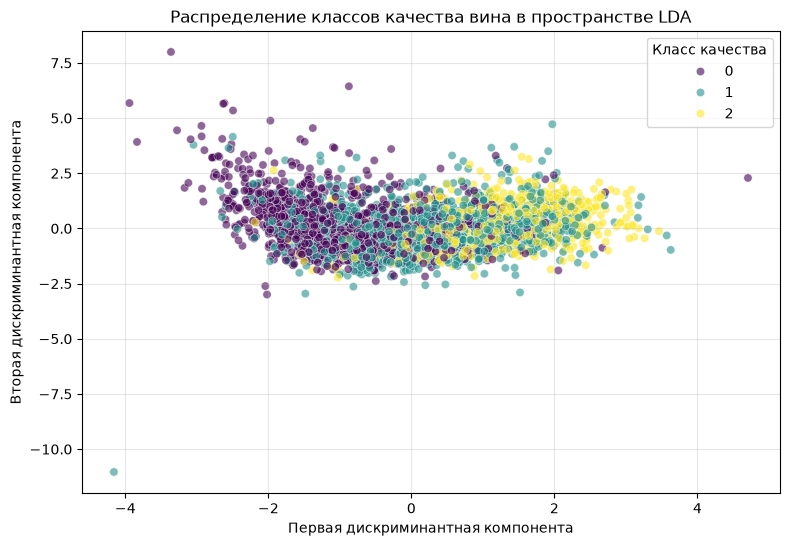

In [32]:
lda_model = LinearDiscriminantAnalysis()

lda_model.fit(X_train_scaler, Y_train)

Y_pred_lda = lda_model.predict(X_test_scaler)

X_train_lda = lda_model.transform(X_train_scaler)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_train_lda[:, 0],
    y=X_train_lda[:, 1],
    hue=Y_train.to_numpy(),
    palette="viridis",
    alpha=0.6
)

plt.xlabel("Первая дискриминантная компонента")
plt.ylabel("Вторая дискриминантная компонента")
plt.title("Распределение классов качества вина в пространстве LDA")
plt.legend(title="Класс качества")
plt.grid(alpha=0.3)
plt.show()

Модель LDA обучена на стандартизованных признаках. Получена проекция обучающих наблюдений на две дискриминантные компоненты. Для трёх классов метод позволяет построить не более двух таких компонент. Диаграмма используется для визуального анализа взаимного расположения классов и не заменяет оценку на тестовых данных.

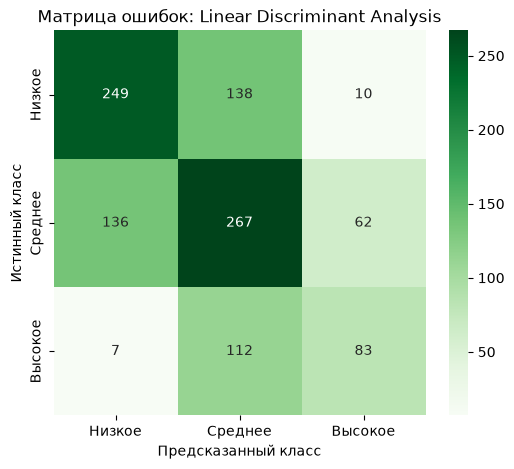

Accuracy: 0.5629699248120301


In [33]:
plot_confusion_matrix(Y_test, Y_pred_lda, "Linear Discriminant Analysis")
print("Accuracy:", accuracy_score(Y_test, Y_pred_lda))

Accuracy LDA составил 56,3%. Правильно классифицированы 249 объектов низкого, 267 объектов среднего и 83 объекта высокого качества. Из 202 объектов высокого качества 112 отнесены к среднему, что указывает на трудности разделения этих категорий.

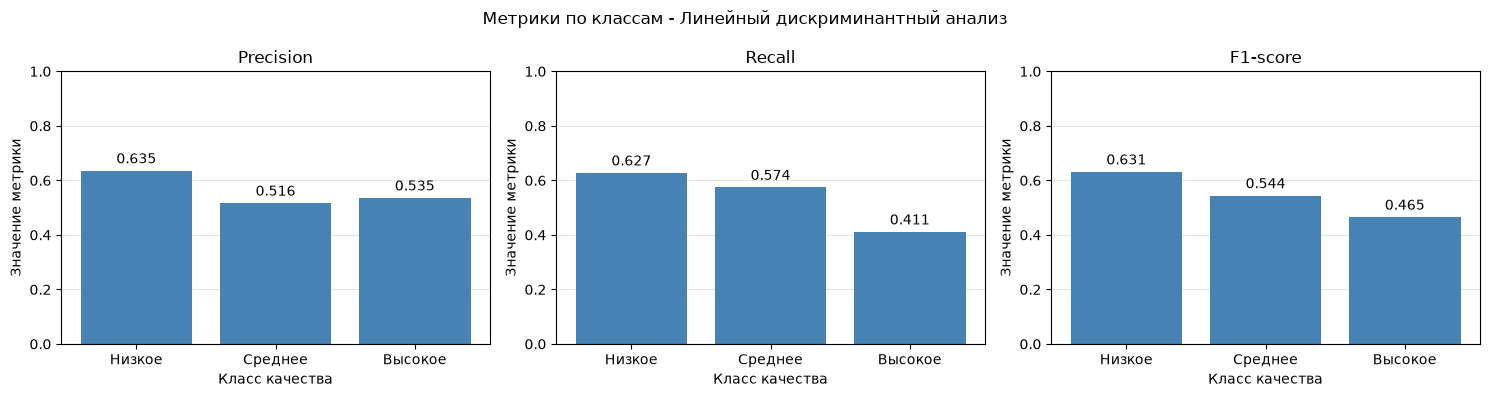

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.635,0.627,0.631
Среднее,0.516,0.574,0.544
Высокое,0.535,0.411,0.465
Макроусреднение,0.562,0.537,0.547


,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.635204,0.627204,0.631179
Среднее,0.516441,0.574194,0.543788
Высокое,0.535484,0.410891,0.464986
Макроусреднение,0.562376,0.537430,0.546651


In [34]:
plot_class_metrics(Y_test, Y_pred_lda, "Линейный дискриминантный анализ")

Лучше всего распознаётся низкое качество: F1-score равен 0,631. Для высокого качества Recall составляет только 0,411.

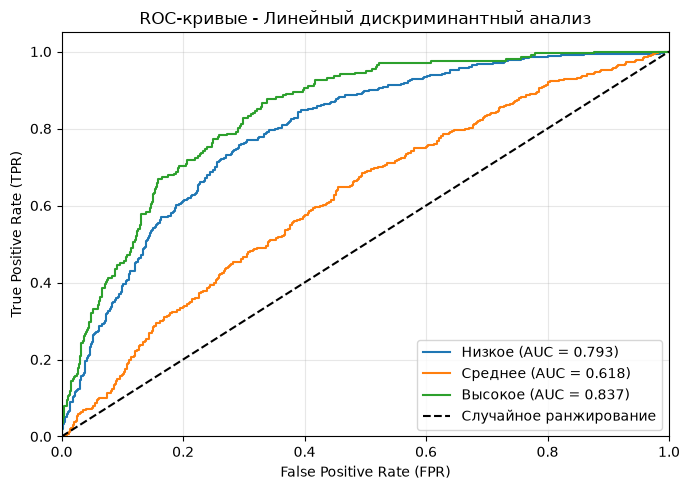

AUC-macro: 0.749


In [35]:
plot_roc(lda_model, X_test_scaler, Y_test, "Линейный дискриминантный анализ")

AUC составил 0,793 для низкого, 0,618 для среднего и 0,837 для высокого качества. AUC-macro равен 0,749. Наиболее высокий AUC получен для высокого качества, хотя Recall этого класса составляет только 0,411. Это показывает различие между способностью ранжировать объекты и результатом выбора итогового класса.

### Метод опорных векторов (SVM)

Support Vector Machines - метод классификации, основанный на построении разделяющей границы с максимальным зазором между классами. Использование ядерных функций позволяет находить нелинейные зависимости между признаками и целевой переменной.

Для обучения используется SVC из библиотеки Scikit-Learn с гиперпараметрами по умолчанию и ядром RBF. Поскольку метод чувствителен к масштабу признаков, применяются предварительно стандартизованные данные.

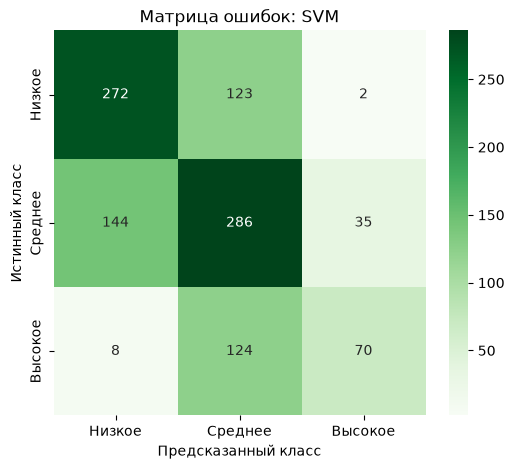

Accuracy: 0.5902255639097744


In [36]:
svm_model = SVC()

svm_model.fit(X_train_scaler, Y_train)

Y_pred_svm = svm_model.predict(X_test_scaler)

plot_confusion_matrix(Y_test, Y_pred_svm, "SVM")
print("Accuracy:", accuracy_score(Y_test, Y_pred_svm))

Accuracy SVM составил 59,0%. Правильно классифицированы 272 объекта низкого, 286 объектов среднего и 70 объектов высокого качества. При этом 124 объекта высокого качества отнесены к среднему.

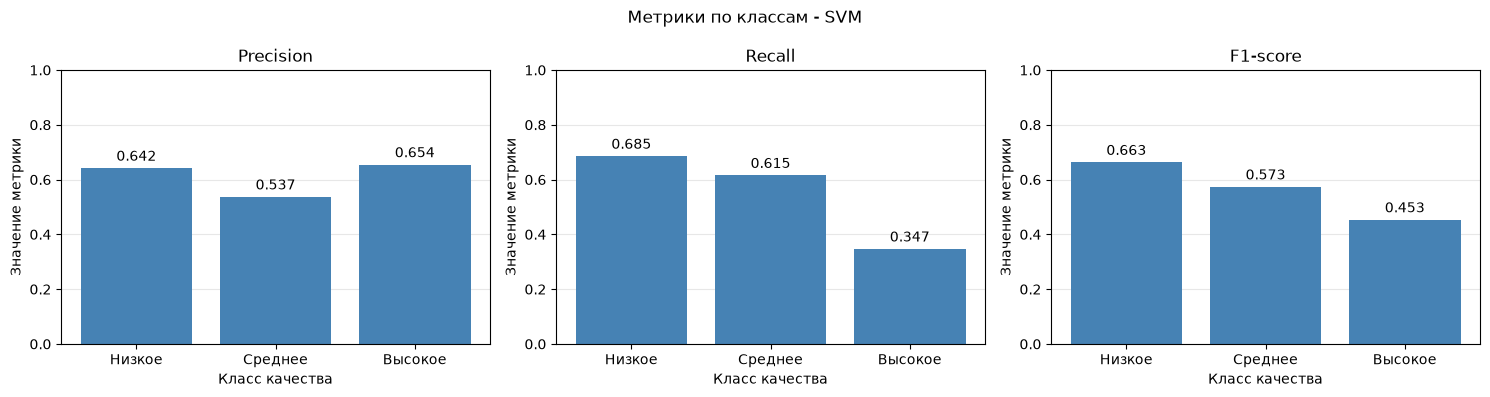

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.642,0.685,0.663
Среднее,0.537,0.615,0.573
Высокое,0.654,0.347,0.453
Макроусреднение,0.611,0.549,0.563


,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.641509,0.685139,0.662607
Среднее,0.536585,0.615054,0.573146
Высокое,0.654206,0.346535,0.453074
Макроусреднение,0.610767,0.548909,0.562942


In [37]:
plot_class_metrics(Y_test, Y_pred_svm, "SVM")

Предсказания высокого качества относительно надёжны (Precision=0,654), но модель обнаруживает лишь около 35% объектов этого класса (Recall=0,347). Наиболее высокий F1-score получен для низкого качества - 0,663.

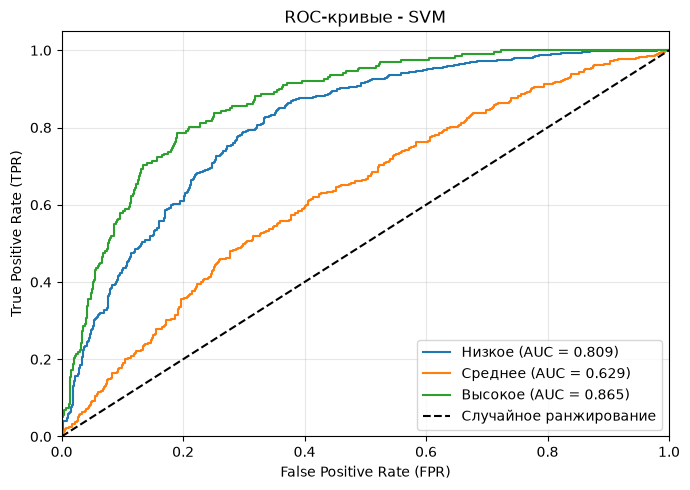

AUC-macro: 0.768


In [38]:
plot_roc(svm_model, X_test_scaler, Y_test, "SVM")

AUC составил 0,809 для низкого, 0,629 для среднего и 0,865 для высокого качества. AUC-macro равен 0,768. Модель хорошо ранжирует объекты высокого качества, однако при текущем правиле выбора класса часто относит их к среднему.

### Метод ближайших соседей (kNN)

k-Nearest Neighbors - метод классификации, определяющий класс объекта на основании классов его ближайших соседей в пространстве признаков. Предсказываемый класс выбирается по большинству голосов среди k ближайших наблюдений.

Для обучения используется KNeighborsClassifier из библиотеки Scikit-Learn с гиперпараметрами по умолчанию (n_neighbors=5). Поскольку алгоритм основан на вычислении расстояний, используются стандартизованные данные.

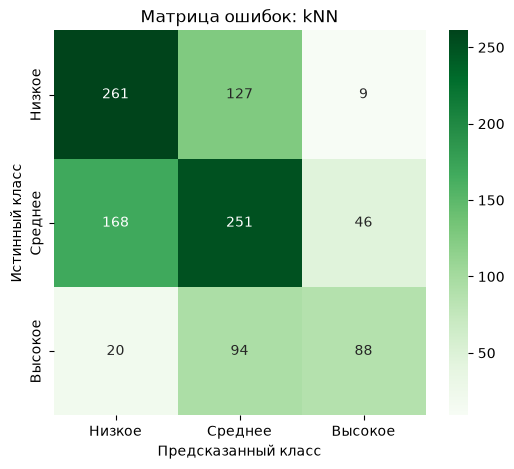

Accuracy: 0.5639097744360902


In [39]:
knn_model = KNeighborsClassifier()

knn_model.fit(X_train_scaler, Y_train)

Y_pred_knn = knn_model.predict(X_test_scaler)

plot_confusion_matrix(Y_test, Y_pred_knn, "kNN")
print("Accuracy:", accuracy_score(Y_test, Y_pred_knn))

Accuracy kNN при числе соседей k=5 составил 56,4%. Правильно классифицированы 261 объект низкого, 251 объект среднего и 88 объектов высокого качества. Основные ошибки связаны со смешением низкого и среднего качества, а также с отнесением высокого качества к среднему.

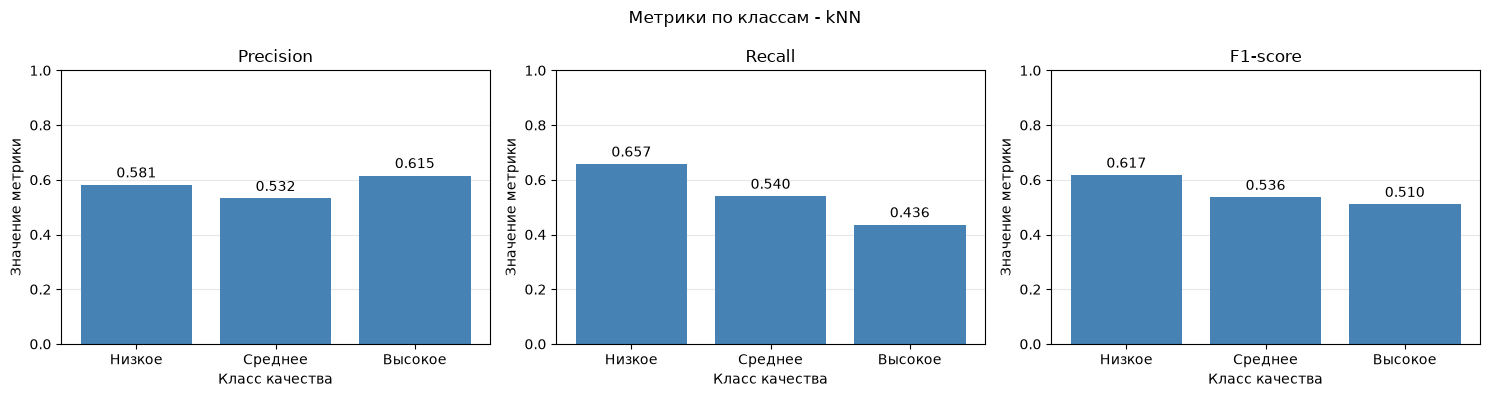

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.581,0.657,0.617
Среднее,0.532,0.540,0.536
Высокое,0.615,0.436,0.510
Макроусреднение,0.576,0.544,0.554


,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.581292,0.657431,0.617021
Среднее,0.531780,0.539785,0.535752
Высокое,0.615385,0.435644,0.510145
Макроусреднение,0.576152,0.544286,0.554306


In [40]:
plot_class_metrics(Y_test, Y_pred_knn, "kNN")

F1-score высокого качества составляет 0,510, что выше, чем у SVM (0,453). Однако общий F1-macro у kNN ниже, поэтому преимущество по одному классу не означает преимущества модели в целом.

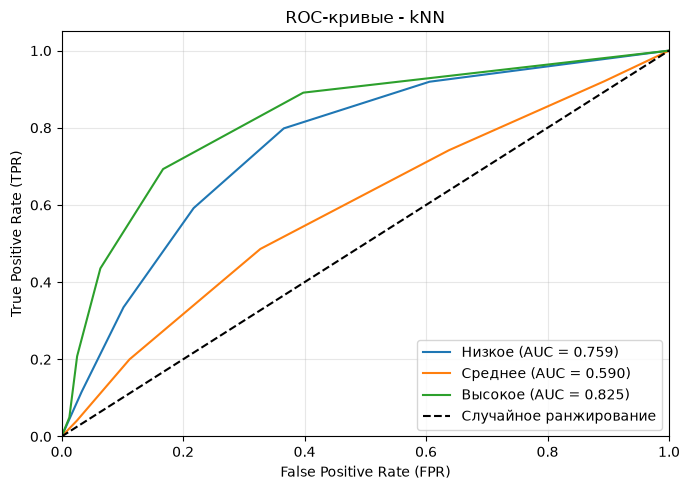

AUC-macro: 0.725


In [41]:
plot_roc(knn_model, X_test_scaler, Y_test, "kNN")

AUC составил 0,759 для низкого, 0,590 для среднего и 0,825 для высокого качества. AUC-macro равен 0,725. Наиболее успешно модель ранжирует объекты высокого качества, а различение среднего качества вызывает наибольшие трудности.

## Сравнение качества работы классификаторов

Качество классификаторов сравнивается на одной и той же тестовой выборке по метрикам Accuracy, Precision-macro, Recall-macro, F1-macro и AUC-macro.

Макроусреднение придаёт одинаковый вес каждому классу независимо от количества его объектов. Основной метрикой сравнения выбран F1-macro, поскольку она совместно учитывает Precision и Recall и позволяет учитывать качество распознавания менее многочисленного класса высокого качества.

AUC-macro рассчитывается как среднее значение AUC для трёх задач «один класс против остальных».

In [42]:
models = [
    ("GaussianNB", gaussian_nb, X_test),
    ("MultinomialNB", multinomial_nb, X_test_minmax),
    ("ComplementNB", complement_nb, X_test_minmax),
    ("BernoulliNB", bernoulli_nb, X_test_binary),
    ("Дерево решений", decision_tree, X_test),
    ("LDA", lda_model, X_test_scaler),
    ("SVM", svm_model, X_test_scaler),
    ("kNN", knn_model, X_test_scaler)
]

results = []

for name, model, test_data in models:
    prediction = model.predict(test_data)

    classes = model.classes_
    y_binary = label_binarize(Y_test, classes=classes)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(test_data)
    else:
        scores = model.decision_function(test_data)

    auc_values = []

    for i in range(len(classes)):
        fpr, tpr, _ = roc_curve(y_binary[:, i], scores[:, i])
        auc_values.append(auc(fpr, tpr))

    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(Y_test, prediction),
        "Precision-macro": precision_score(
            Y_test, prediction, average="macro", zero_division=0
        ),
        "Recall-macro": recall_score(
            Y_test, prediction, average="macro", zero_division=0
        ),
        "F1-macro": f1_score(
            Y_test, prediction, average="macro", zero_division=0
        ),
        "AUC-macro": np.mean(auc_values)
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("F1-macro", ascending=False)
    .reset_index(drop=True)
)

display(results_df.round(3))

,Модель,Accuracy,Precision-macro,Recall-macro,F1-macro,AUC-macro
0,SVM,0.590,0.611,0.549,0.563,0.768
1,kNN,0.564,0.576,0.544,0.554,0.725
2,LDA,0.563,0.562,0.537,0.547,0.749
3,Дерево решений,0.525,0.515,0.515,0.515,0.631
4,BernoulliNB,0.492,0.483,0.515,0.489,0.683
5,GaussianNB,0.483,0.483,0.512,0.487,0.690
6,ComplementNB,0.446,0.444,0.467,0.444,0.664
7,MultinomialNB,0.449,0.306,0.356,0.307,0.663


Среди моделей с исходными гиперпараметрами наибольший F1-macro получен у SVM - 0,563. Этот классификатор также показал наибольшие Accuracy (0,590), Precision-macro (0,611), Recall-macro (0,549) и AUC-macro (0,768).

Близкие результаты по F1-macro получены у kNN (0,554) и LDA (0,547). Наименьший F1-macro показал MultinomialNB (0,307), который не предсказал ни одного объекта высокого качества.

При этом преимущество SVM по общим показателям не означает, что он лучше распознаёт каждый класс: для высокого качества F1-score у kNN выше - 0,510 против 0,453 у SVM. Следовательно, при выборе модели необходимо учитывать как общие метрики, так и результаты по отдельным классам.

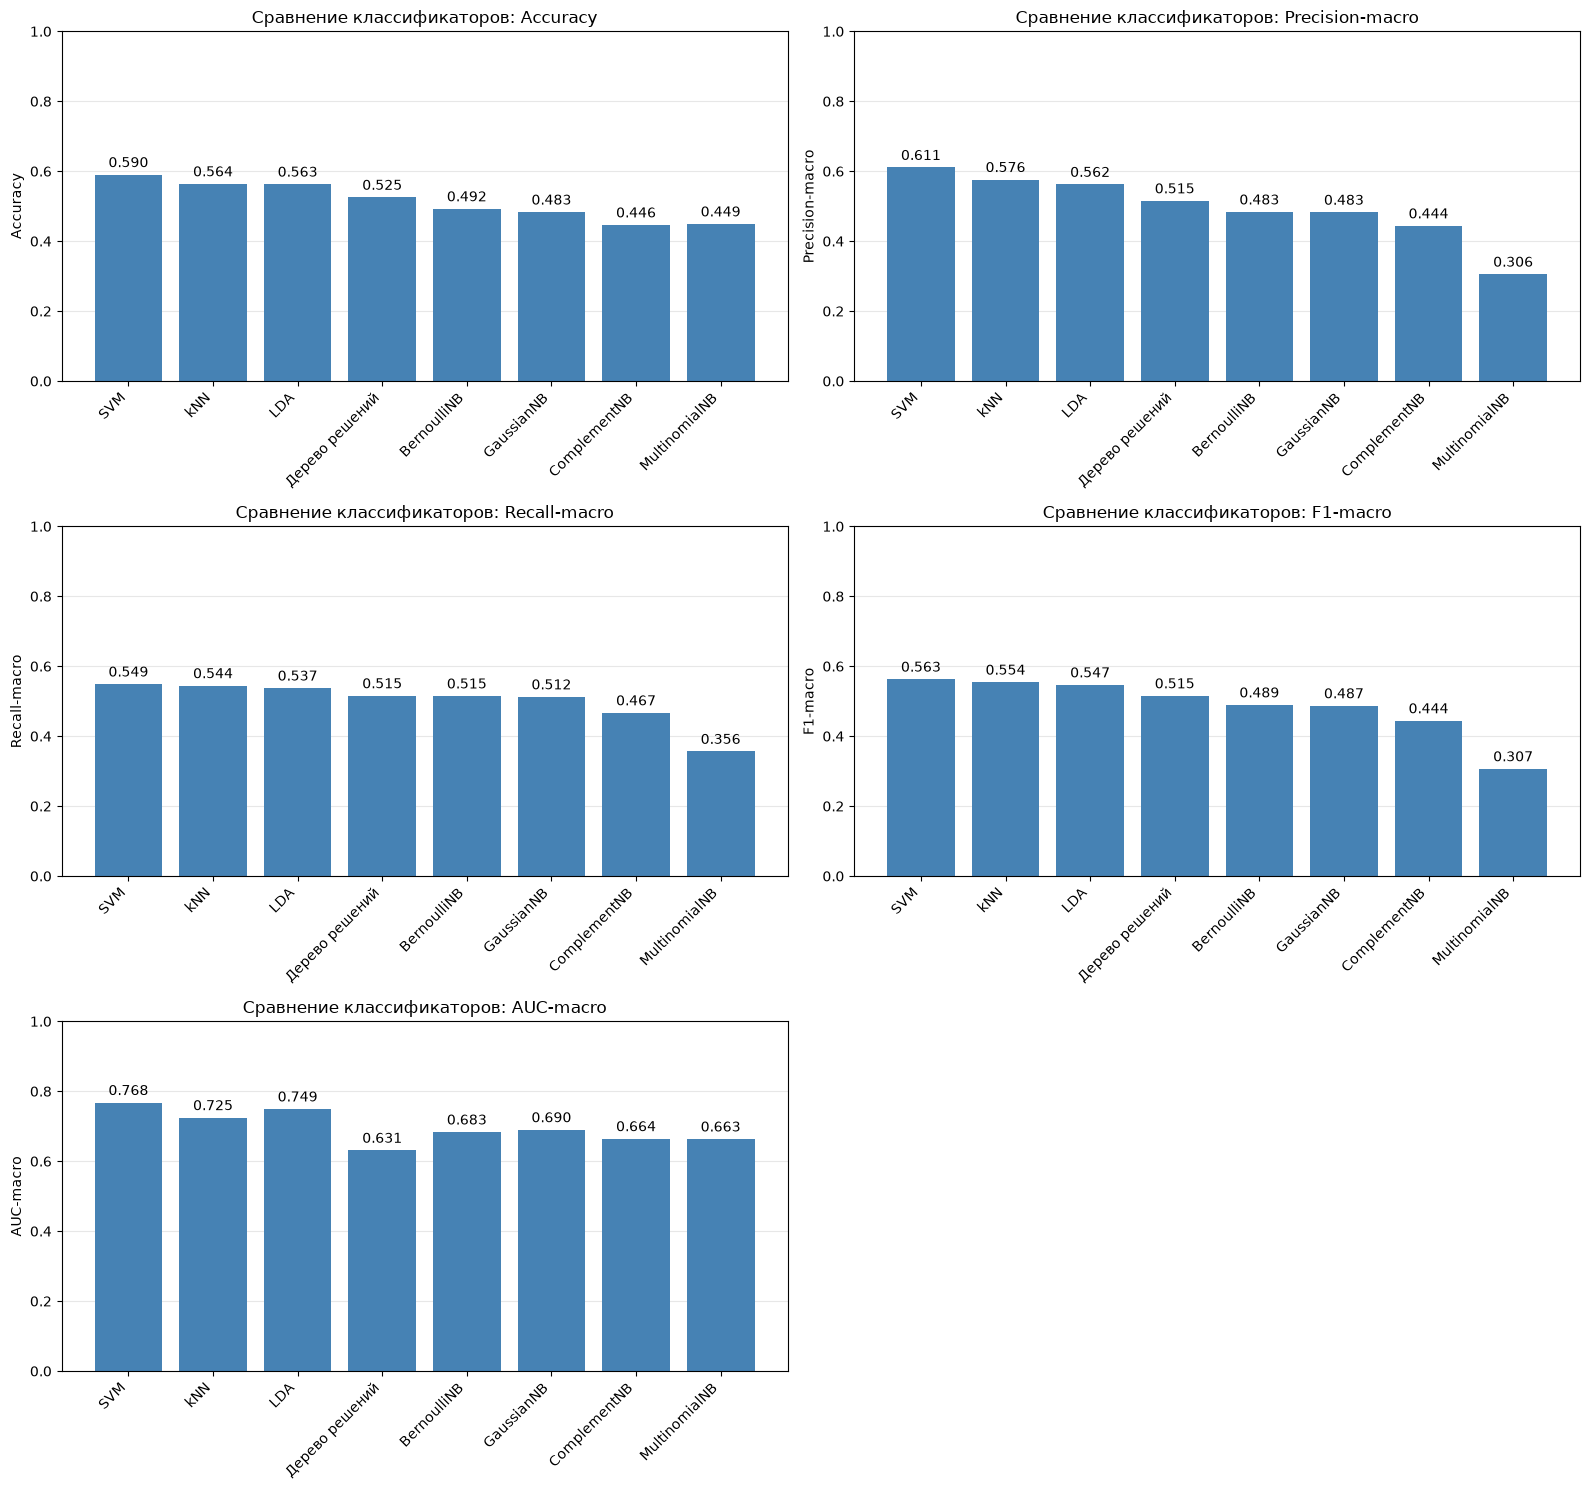

In [43]:
metrics = [
    "Accuracy",
    "Precision-macro",
    "Recall-macro",
    "F1-macro",
    "AUC-macro"
]

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.ravel()

for ax, metric in zip(axes, metrics):
    bars = ax.bar(
        results_df["Модель"],
        results_df[metric],
        color="steelblue"
    )

    ax.set_title(f"Сравнение классификаторов: {metric}")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelrotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

    ax.bar_label(bars, fmt="%.3f", padding=3)

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

Диаграммы подтверждают преимущество SVM по выбранным общим показателям. kNN и LDA демонстрируют близкие результаты и также заслуживают дальнейшего исследования.

Особенно заметно снижение Precision-macro, Recall-macro и F1-macro у MultinomialNB. При этом его Accuracy отличается от ComplementNB незначительно. Это показывает, что одной Accuracy недостаточно для оценки многоклассовой классификации при неравномерном распределении классов.

## Настройка гиперпараметров классификаторов

Для исследования влияния гиперпараметров используется перебор комбинаций с помощью GridSearchCV. Каждая комбинация оценивается по пятиблочной стратифицированной кросс-валидации на обучающей выборке. При этом четыре части используются для обучения, а оставшаяся - для валидации; процедура повторяется пять раз.

Критерием выбора является средний F1-macro на валидационных частях. Все модели используют одинаковые разбиения. Тестовая выборка не участвует в подборе параметров.

Предобработка включается в Pipeline, поэтому параметры масштабирования и пороги бинаризации определяются заново на обучающей части каждого разбиения.

In [44]:
class MedianBinarizer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.medians_ = np.median(np.asarray(X), axis=0)
        return self

    def transform(self, X):
        return (np.asarray(X) > self.medians_).astype(int)


numeric_features = X_train.columns.drop("Тип").tolist()


def make_preprocessor(transformer):
    return ColumnTransformer(
        transformers=[
            ("numeric", transformer, numeric_features),
            ("type", "passthrough", ["Тип"])
        ]
    )


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

Подготовлены единые разбиения для кросс-валидации и средства предобработки. Числовые признаки будут преобразовываться внутри каждого обучающего разбиения, а бинарный признак «Тип» будет передаваться без изменений.

Для дальнейшего подбора используются исходные X_train и Y_train: необходимые преобразования выполняются непосредственно внутри Pipeline.

Для каждого классификатора задаются исследуемые гиперпараметры и несколько их значений. В сетки включены исходные настройки моделей, чтобы сравнить их с альтернативными конфигурациями.

Для дерева решений, SVM и kNN проверяются параметры, влияющие на сложность модели. Для наивного Байеса исследуется сглаживание и дополнительные настройки. Для LDA рассматриваются разные способы вычисления и регуляризация ковариационной матрицы.

Основные исследуемые настройки:

| Модель | Назначение параметров |
|---|---|
| GaussianNB | var_smoothing задаёт добавку к дисперсиям для устойчивости вычислений |
| MultinomialNB, BernoulliNB | alpha регулирует сглаживание; fit_prior определяет использование частот классов для оценки априорных вероятностей |
| ComplementNB | alpha регулирует сглаживание; norm включает дополнительную нормировку весов |
| Дерево решений | max_depth ограничивает глубину; min_samples_leaf - минимальное число объектов в листе; class_weight задаёт веса классов |
| LDA | solver выбирает способ вычисления; shrinkage регулирует оценку ковариационной матрицы |
| SVM | C регулирует штраф за ошибки; gamma влияет на локальность ядра RBF; kernel выбирает тип ядра |
| kNN | n_neighbors задаёт число соседей; weights - способ взвешивания голосов; p - вид расстояния Минковского |

In [45]:
experiments = {
    "GaussianNB": {
        "pipeline": Pipeline([
            ("model", GaussianNB())
        ]),
        "params": {
            "model__var_smoothing": [
                1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-1
            ]
        }
    },

    "MultinomialNB": {
        "pipeline": Pipeline([
            ("prep", make_preprocessor(MinMaxScaler(clip=True))),
            ("model", MultinomialNB())
        ]),
        "params": {
            "model__alpha": [0.01, 0.1, 1.0, 10.0],
            "model__fit_prior": [True, False]
        }
    },

    "ComplementNB": {
        "pipeline": Pipeline([
            ("prep", make_preprocessor(MinMaxScaler(clip=True))),
            ("model", ComplementNB())
        ]),
        "params": {
            "model__alpha": [0.01, 0.1, 1.0, 10.0],
            "model__norm": [False, True]
        }
    },

    "BernoulliNB": {
        "pipeline": Pipeline([
            ("prep", make_preprocessor(MedianBinarizer())),
            ("model", BernoulliNB(binarize=None))
        ]),
        "params": {
            "model__alpha": [0.01, 0.1, 1.0, 10.0],
            "model__fit_prior": [True, False]
        }
    },

    "Дерево решений": {
        "pipeline": Pipeline([
            ("model", DecisionTreeClassifier(random_state=42))
        ]),
        "params": {
            "model__max_depth": [3, 5, 10, None],
            "model__min_samples_leaf": [1, 5, 10],
            "model__class_weight": [None, "balanced"]
        }
    },

    "LDA": {
        "pipeline": Pipeline([
            ("prep", make_preprocessor(StandardScaler())),
            ("model", LinearDiscriminantAnalysis())
        ]),
        "params": [
            {
                "model__solver": ["svd"],
                "model__shrinkage": [None]
            },
            {
                "model__solver": ["lsqr"],
                "model__shrinkage": [None, "auto", 0.1, 0.5, 1.0]
            }
        ]
    },

    "SVM": {
        "pipeline": Pipeline([
            ("prep", make_preprocessor(StandardScaler())),
            ("model", SVC())
        ]),
        "params": [
            {
                "model__kernel": ["linear"],
                "model__C": [0.1, 1.0, 10.0]
            },
            {
                "model__kernel": ["rbf"],
                "model__C": [0.1, 1.0, 10.0],
                "model__gamma": ["scale", 0.01, 0.1, 1.0]
            }
        ]
    },

    "kNN": {
        "pipeline": Pipeline([
            ("prep", make_preprocessor(StandardScaler())),
            ("model", KNeighborsClassifier())
        ]),
        "params": {
            "model__n_neighbors": [3, 5, 9, 15, 25],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    }
}

Сформированы сетки параметров для восьми классификаторов. Числовые признаки стандартизуются для LDA, SVM и kNN, масштабируются в неотрицательный диапазон для MultinomialNB и ComplementNB и бинаризуются для BernoulliNB. GaussianNB и дерево решений используют исходные признаки.

Для LDA заданы отдельные сетки, поскольку solver="svd" не поддерживает регуляризацию shrinkage. Для SVM параметр gamma исследуется только при использовании ядра RBF.

Для каждой модели выполняется перебор заданных комбинаций гиперпараметров. Сохраняются средние значения F1-macro на обучающих и валидационных частях, стандартное отклонение валидационной оценки и лучшие параметры.

Сравнение обучающих и валидационных оценок помогает выявить признаки переобучения. Стандартное отклонение характеризует изменчивость результата между пятью разбиениями.

In [46]:
searches = {}
experiment_tables = {}
best_rows = []

for name, experiment in experiments.items():
    print(f"\nПодбор параметров: {name}")

    search = GridSearchCV(
        estimator=experiment["pipeline"],
        param_grid=experiment["params"],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, Y_train)
    searches[name] = search

    table = pd.DataFrame(search.cv_results_["params"])

    table.columns = [
        column.replace("model__", "")
        for column in table.columns
    ]

    table["F1-macro train"] = search.cv_results_["mean_train_score"]
    table["F1-macro validation"] = search.cv_results_["mean_test_score"]
    table["STD validation"] = search.cv_results_["std_test_score"]

    table = table.sort_values(
        "F1-macro validation",
        ascending=False
    ).reset_index(drop=True)

    experiment_tables[name] = table

    print("Результаты всех комбинаций:")
    display(table.round(4))

    best_params = {
        key.replace("model__", ""): value
        for key, value in search.best_params_.items()
    }

    best_rows.append({
        "Модель": name,
        "Лучшие параметры": best_params,
        "F1-macro CV": search.best_score_,
        "STD CV": search.cv_results_["std_test_score"][
            search.best_index_
        ]
    })

best_params_df = (
    pd.DataFrame(best_rows)
    .sort_values("F1-macro CV", ascending=False)
    .reset_index(drop=True)
)

print("\nЛучшие конфигурации:")
display(best_params_df.round(4))


Подбор параметров: GaussianNB
Результаты всех комбинаций:


,var_smoothing,F1-macro train,F1-macro validation,STD validation
0,0.000,0.5238,0.5154,0.0107
1,0.000,0.5041,0.5000,0.0187
2,0.000,0.4954,0.4912,0.0126
3,0.000,0.4944,0.4867,0.0138
4,0.001,0.4048,0.4064,0.0184
5,0.100,0.2619,0.2596,0.0090



Подбор параметров: MultinomialNB
Результаты всех комбинаций:


,alpha,fit_prior,F1-macro train,F1-macro validation,STD validation
0,0.10,False,0.4114,0.4083,0.0251
1,0.01,False,0.4117,0.4081,0.0250
2,1.00,False,0.4100,0.4073,0.0263
3,10.00,False,0.4004,0.3979,0.0309
4,10.00,True,0.3269,0.3270,0.0089
5,1.00,True,0.3260,0.3262,0.0085
6,0.10,True,0.3260,0.3262,0.0085
7,0.01,True,0.3261,0.3262,0.0085



Подбор параметров: ComplementNB
Результаты всех комбинаций:


...

,C,kernel,gamma,F1-macro train,F1-macro validation,STD validation
0,10.0,rbf,0.1,0.7187,0.5847,0.0117
1,10.0,rbf,scale,0.7037,0.5841,0.0138
2,1.0,rbf,0.1,0.6302,0.5799,0.0151
3,1.0,rbf,scale,0.6253,0.5774,0.0168
4,1.0,rbf,1.0,0.9003,0.5621,0.0132
5,10.0,rbf,0.01,0.5747,0.5593,0.0188
6,10.0,rbf,1.0,0.9970,0.5585,0.0128
7,10.0,linear,NaN,0.5188,0.5067,0.0401
8,1.0,linear,NaN,0.5160,0.5040,0.0389
9,0.1,rbf,0.1,0.4958,0.4832,0.0196



Подбор параметров: kNN
Результаты всех комбинаций:


,n_neighbors,p,weights,F1-macro train,F1-macro validation,STD validation
0,15,1,distance,1.0000,0.5903,0.0126
1,9,1,distance,1.0000,0.5893,0.0108
2,15,2,distance,1.0000,0.5857,0.0144
3,25,1,distance,1.0000,0.5856,0.0047
4,25,2,distance,1.0000,0.5807,0.0128
5,9,2,distance,1.0000,0.5807,0.0152
6,5,1,distance,1.0000,0.5798,0.0166
7,5,2,distance,1.0000,0.5742,0.0156
8,15,1,uniform,0.6300,0.5734,0.0124
9,3,1,distance,1.0000,0.5717,0.0142



Лучшие конфигурации:


,Модель,Лучшие параметры,F1-macro CV,STD CV
0,kNN,"{'n_neighbors': 15, 'p': 1, 'weights': 'distan...",0.5903,0.0126
1,SVM,"{'C': 10.0, 'gamma': 0.1, 'kernel': 'rbf'}",0.5847,0.0117
2,LDA,"{'shrinkage': None, 'solver': 'svd'}",0.5632,0.0119
3,Дерево решений,"{'class_weight': None, 'max_depth': 5, 'min_sa...",0.5473,0.0177
4,GaussianNB,{'var_smoothing': 1e-05},0.5154,0.0107
5,BernoulliNB,"{'alpha': 10.0, 'fit_prior': True}",0.4948,0.0209
6,ComplementNB,"{'alpha': 1.0, 'norm': False}",0.4452,0.0185
7,MultinomialNB,"{'alpha': 0.1, 'fit_prior': False}",0.4083,0.0251


По результатам пятиблочной кросс-валидации наибольший средний F1-macro получен у kNN - 0,5903. Лучшая конфигурация использует 15 соседей, взвешивание голосов по расстоянию и манхэттенское расстояние (p=1).

Второй результат показал SVM с ядром RBF, C=10 и gamma=0,1: F1-macro составил 0,5847. Разница между kNN и SVM равна примерно 0,0056 и невелика относительно изменчивости оценок между разбиениями. Поэтому результаты не позволяют утверждать, что kNN имеет существенное преимущество.

Для LDA выбрана конфигурация solver="svd" без регуляризации, для дерева решений - max_depth = 5, min_samples_leaf=1 и class_weight=None. Среди вариантов наивного Байеса наибольший F1-macro на кросс-валидации показал GaussianNB при var_smoothing=10^-5.

Выбранные конфигурации являются лучшими среди проверенных комбинаций.

Для наглядного исследования строятся графики зависимости F1-macro от одного выбранного гиперпараметра каждой модели.

Остальные параметры фиксируются на значениях лучшей конфигурации. Для LDA исследуется shrinkage при solver="lsqr", а для SVM - C при ядре RBF. На графиках сопоставляются средние обучающие и валидационные оценки.


GaussianNB: влияние var_smoothing
Зафиксированные параметры: {}


,Значение параметра,Train,Validation
0,1e-11,0.4944,0.4867
1,1e-09,0.4954,0.4912
2,1e-07,0.5041,0.5000
3,1e-05,0.5238,0.5154
4,0.001,0.4048,0.4064
5,0.1,0.2619,0.2596


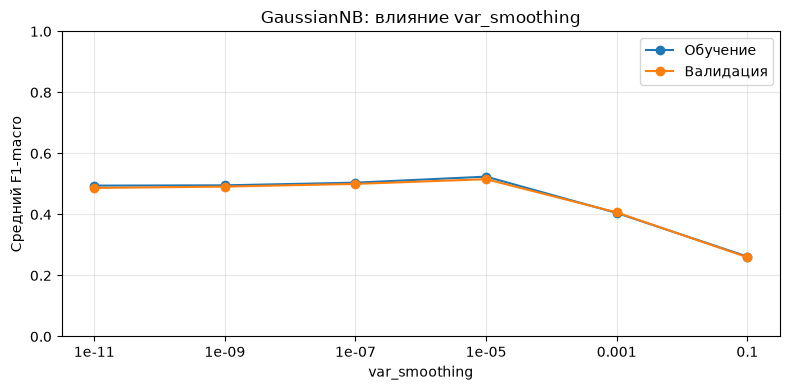


MultinomialNB: влияние alpha
Зафиксированные параметры: {'fit_prior': False}


,Значение параметра,Train,Validation
0,0.01,0.4117,0.4081
1,0.1,0.4114,0.4083
2,1.0,0.4100,0.4073
3,10.0,0.4004,0.3979


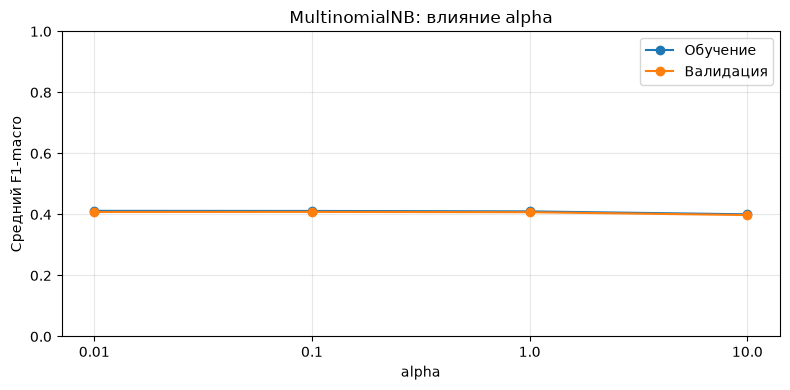


ComplementNB: влияние alpha
Зафиксированные параметры: {'norm': False}


,Значение параметра,Train,Validation
0,0.01,0.4425,0.4447
1,0.1,0.4424,0.4447
2,1.0,0.4425,0.4452
3,10.0,0.4419,0.4452


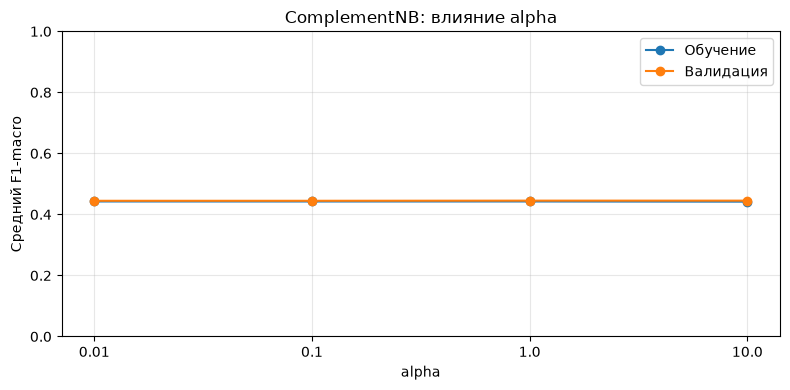


BernoulliNB: влияние alpha
Зафиксированные параметры: {'fit_prior': True}


,Значение параметра,Train,Validation
0,0.01,0.4932,0.4940
1,0.1,0.4932,0.4940
2,1.0,0.4929,0.4939
3,10.0,0.4943,0.4948


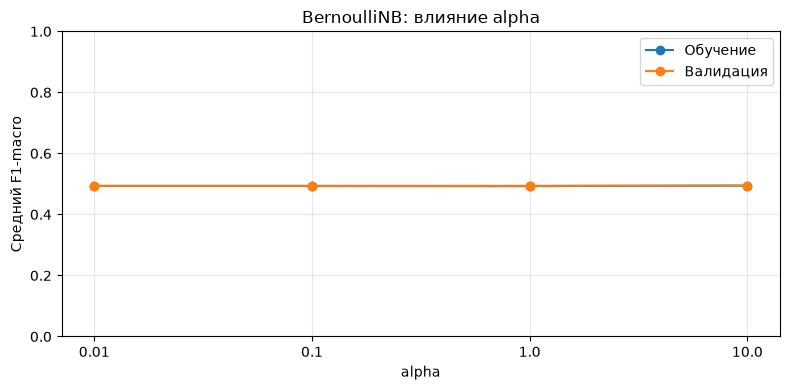


Дерево решений: влияние max_depth
Зафиксированные параметры: {'class_weight': None, 'min_samples_leaf': 1}


,Значение параметра,Train,Validation
0,3,0.5287,0.5047
1,5,0.5977,0.5473
2,10,0.7813,0.5289
3,None,1.0000,0.5123


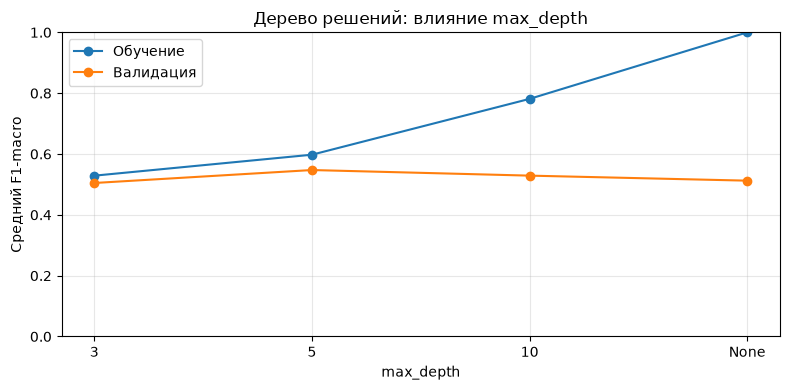


LDA: влияние shrinkage
Зафиксированные параметры: {'solver': 'lsqr'}


,Значение параметра,Train,Validation
0,None,0.5702,0.5632
1,auto,0.5686,0.5605
2,0.1,0.5638,0.5603
3,0.5,0.5554,0.5498
4,1.0,0.5293,0.5272


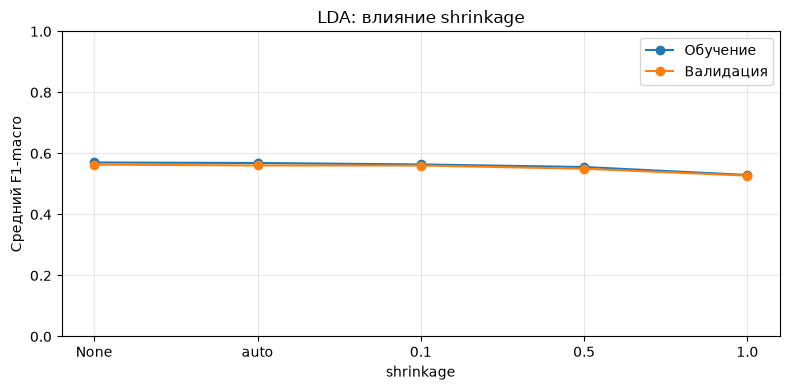


SVM: влияние C
Зафиксированные параметры: {'gamma': 0.1, 'kernel': 'rbf'}


,Значение параметра,Train,Validation
0,0.1,0.4958,0.4832
1,1.0,0.6302,0.5799
2,10.0,0.7187,0.5847


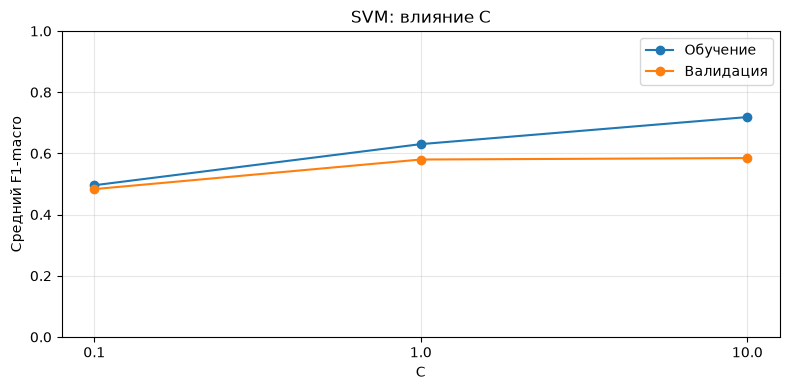


kNN: влияние n_neighbors
Зафиксированные параметры: {'p': 1, 'weights': 'distance'}


,Значение параметра,Train,Validation
0,3,1.0,0.5717
1,5,1.0,0.5798
2,9,1.0,0.5893
3,15,1.0,0.5903
4,25,1.0,0.5856


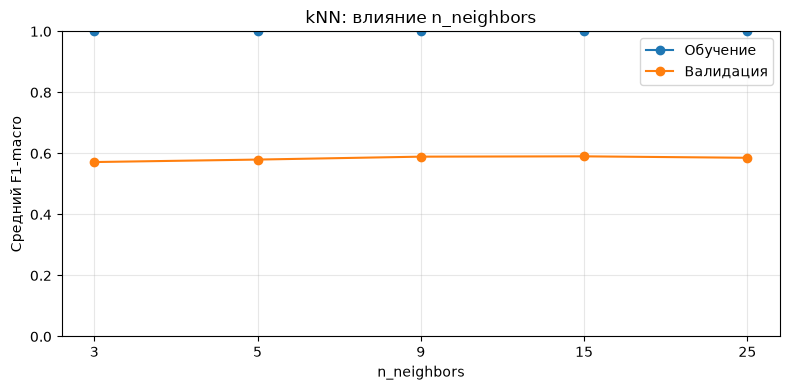

In [47]:
parameter_studies = {
    "GaussianNB": ("model__var_smoothing", {}),
    "MultinomialNB": ("model__alpha", {}),
    "ComplementNB": ("model__alpha", {}),
    "BernoulliNB": ("model__alpha", {}),
    "Дерево решений": ("model__max_depth", {}),
    "LDA": ("model__shrinkage", {"model__solver": "lsqr"}),
    "SVM": ("model__C", {"model__kernel": "rbf"}),
    "kNN": ("model__n_neighbors", {})
}

for name, (parameter, overrides) in parameter_studies.items():
    search = searches[name]

    fixed_params = search.best_params_.copy()
    fixed_params.update(overrides)
    
    if name == "SVM":
        fixed_params.setdefault("model__gamma", "scale")

    rows = []

    for i, params in enumerate(search.cv_results_["params"]):
        suitable = all(
            params.get(key) == value
            for key, value in fixed_params.items()
            if key != parameter
        )

        if suitable and parameter in params:
            rows.append({
                "Значение параметра": str(params[parameter]),
                "Train": search.cv_results_["mean_train_score"][i],
                "Validation": search.cv_results_["mean_test_score"][i]
            })

    study_df = pd.DataFrame(rows)

    short_parameter = parameter.replace("model__", "")

    print(f"\n{name}: влияние {short_parameter}")
    print("Зафиксированные параметры:", {
        key.replace("model__", ""): value
        for key, value in fixed_params.items()
        if key != parameter
    })
    display(study_df.round(4))

    plt.figure(figsize=(8, 4))

    plt.plot(
        study_df["Значение параметра"],
        study_df["Train"],
        marker="o",
        label="Обучение"
    )

    plt.plot(
        study_df["Значение параметра"],
        study_df["Validation"],
        marker="o",
        label="Валидация"
    )

    plt.title(f"{name}: влияние {short_parameter}")
    plt.xlabel(short_parameter)
    plt.ylabel("Средний F1-macro")
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Анализ влияния гиперпараметров

- **GaussianNB.** Увеличение var_smoothing до 10^-5 повысило валидационный F1-macro до 0,5154. Дальнейшее усиление сглаживания ухудшило качество: при значении 0,1 показатель снизился до 0,2596.

- **MultinomialNB.** Наиболее заметное улучшение связано с fit_prior=False: использование равных априорных вероятностей классов повысило F1-macro примерно с 0,326 до 0,408. Изменение alpha повлияло слабее; лучшим значением стало 0,1.

- **ComplementNB.** При norm=False изменение alpha почти не влияло на качество: F1-macro оставался около 0,445. Включение norm=True снижало результат. Лучшие параметры - alpha=1 и norm=False.

- **BernoulliNB.** При fit_prior=True изменение alpha практически не влияло на F1-macro. Максимум 0,4948 получен при alpha=10, но преимущество над другими значениями невелико. При fit_prior=False качество снижалось примерно до 0,459.

- **Дерево решений.** Увеличение глубины с 3 до 5 повысило валидационный F1-macro с 0,5047 до 0,5473. Дальнейший рост глубины улучшал обучающую оценку, но ухудшал валидационную, что указывает на переобучение. Лучшие параметры - max_depth=5, min_samples_leaf=1 и class_weight=None.

- **LDA.** Без регуляризации solver="svd" и solver="lsqr" показали одинаковый F1-macro с точностью до четырёх знаков - 0,5632. Применение shrinkage не улучшило результат, а усиление регуляризации снижало качество. Выбраны исходные параметры solver="svd" и shrinkage=None.

- **SVM.** При ядре RBF и gamma=0,1 увеличение C с 0,1 до 10 повысило валидационный F1-macro с 0,4832 до 0,5847. При C=10 увеличение gamma до 1 привело к росту обучающей оценки почти до 1 и снижению валидационной, что указывает на переобучение. Лучшие параметры - kernel="rbf", C=10 и gamma=0,1.

- **kNN.** При weights="distance" и p=1 увеличение числа соседей с 3 до 15 повысило валидационный F1-macro с 0,5717 до 0,5903; при 25 соседях результат немного снизился. Взвешивание по расстоянию и манхэттенское расстояние оказались успешнее соответствующих альтернатив при 15 соседях. Лучшие параметры - n_neighbors=15, weights="distance" и p=1.
Обучающий F1-macro при weights="distance" равен 1, поскольку при оценке обучающих объектов каждый объект присутствует среди собственных соседей с нулевым расстоянием. Поэтому этот результат не означает идеального качества на новых данных; для выбора параметров используется валидационная оценка.

Наибольшие средние значения F1-macro на кросс-валидации получены у kNN (0,5903) и SVM (0,5847). Их различие невелико относительно изменчивости оценок между разбиениями. Все выбранные параметры являются лучшими только среди проверенных комбинаций; итоговое качество оценивается отдельно на тестовой выборке.

После завершения подбора лучшие конфигурации оцениваются на тестовой выборке по Accuracy, Precision-macro, Recall-macro, F1-macro и AUC-macro.

Полученные результаты сопоставляются с моделями с исходными гиперпараметрами. Дополнительно рассчитывается изменение F1-macro, выбранного основным показателем сравнения.

In [48]:
tuned_results = []

for name, search in searches.items():
    model = search.best_estimator_

    prediction = model.predict(X_test)

    classes = model.classes_
    y_binary = label_binarize(Y_test, classes=classes)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)
    else:
        scores = model.decision_function(X_test)

    auc_values = []

    for i in range(len(classes)):
        fpr, tpr, _ = roc_curve(y_binary[:, i], scores[:, i])
        auc_values.append(auc(fpr, tpr))

    tuned_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(Y_test, prediction),
        "Precision-macro": precision_score(
            Y_test, prediction, average="macro", zero_division=0
        ),
        "Recall-macro": recall_score(
            Y_test, prediction, average="macro", zero_division=0
        ),
        "F1-macro": f1_score(
            Y_test, prediction, average="macro", zero_division=0
        ),
        "AUC-macro": np.mean(auc_values)
    })

tuned_results_df = pd.DataFrame(tuned_results)

comparison_df = results_df.merge(
    tuned_results_df,
    on="Модель",
    suffixes=(" до", " после")
)

comparison_df["Изменение F1-macro"] = (
    comparison_df["F1-macro после"]
    - comparison_df["F1-macro до"]
)

comparison_df = comparison_df.sort_values(
    "F1-macro после",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(3))

,Модель,Accuracy до,Precision-macro до,Recall-macro до,F1-macro до,AUC-macro до,Accuracy после,Precision-macro после,Recall-macro после,F1-macro после,AUC-macro после,Изменение F1-macro
0,SVM,0.590,0.611,0.549,0.563,0.768,0.587,0.593,0.561,0.571,0.761,0.008
1,kNN,0.564,0.576,0.544,0.554,0.725,0.578,0.581,0.564,0.571,0.757,0.016
2,Дерево решений,0.525,0.515,0.515,0.515,0.631,0.574,0.579,0.538,0.549,0.731,0.034
3,LDA,0.563,0.562,0.537,0.547,0.749,0.563,0.562,0.537,0.547,0.749,0.000
4,GaussianNB,0.483,0.483,0.512,0.487,0.690,0.534,0.533,0.524,0.528,0.711,0.041
5,BernoulliNB,0.492,0.483,0.515,0.489,0.683,0.492,0.483,0.512,0.489,0.684,-0.001
6,ComplementNB,0.446,0.444,0.467,0.444,0.664,0.446,0.444,0.467,0.444,0.664,0.000
7,MultinomialNB,0.449,0.306,0.356,0.307,0.663,0.402,0.414,0.462,0.405,0.661,0.099


### Сравнение качества до и после настройки

Настройка гиперпараметров по-разному повлияла на классификаторы. Наибольший прирост тестового F1-macro получен у MultinomialNB - около 0,099. При этом его Accuracy снизился с 0,449 до 0,402, а Recall-macro вырос с 0,356 до 0,462. Это показывает, что улучшение макроусреднённых показателей может сопровождаться снижением общей доли правильных ответов.

У GaussianNB F1-macro увеличился примерно на 0,041, у дерева решений - на 0,034, у kNN - на 0,016, у SVM - на 0,008. Для LDA и ComplementNB лучшие параметры совпали с исходными, поэтому тестовые результаты не изменились. У BernoulliNB изменение было незначительным: небольшое улучшение на кросс-валидации не привело к улучшению тестового F1-macro.

После настройки наибольший тестовый F1-macro показали SVM и kNN: оба значения округляются до 0,571. В таблице SVM расположен выше, однако разница между моделями мала и не позволяет утверждать о существенном преимуществе одной из них.

Наибольшие тестовые Accuracy (0,587), Precision-macro (0,593) и AUC-macro (0,761) получены у SVM. Наибольший Recall-macro получен у kNN - 0,564.

Настройка улучшила F1-macro нескольких моделей, но не всех. Наиболее успешными по итоговому F1-macro остаются SVM и kNN.

Для классификаторов с подобранными гиперпараметрами строятся матрицы ошибок и ROC-кривые, а также выводятся показатели Precision, Recall и F1-score по классам.


GaussianNB после настройки
Accuracy: 0.534


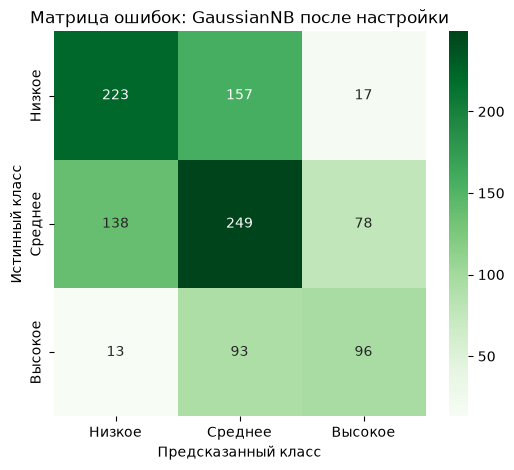

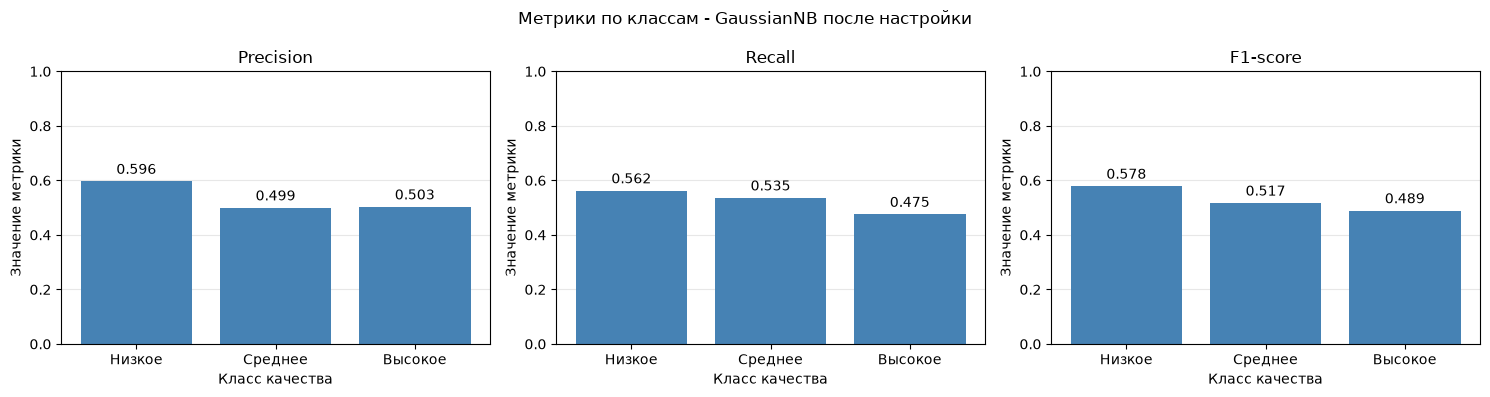

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.596,0.562,0.578
Среднее,0.499,0.535,0.517
Высокое,0.503,0.475,0.489
Макроусреднение,0.533,0.524,0.528


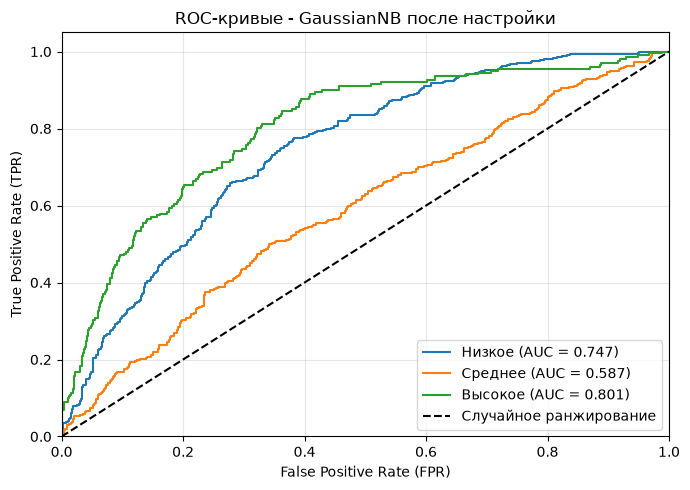

AUC-macro: 0.711

MultinomialNB после настройки
Accuracy: 0.402


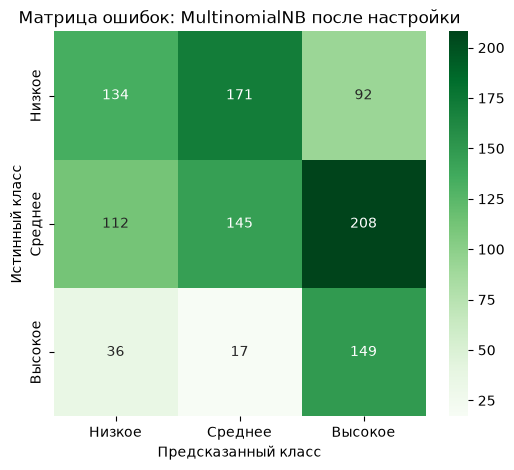

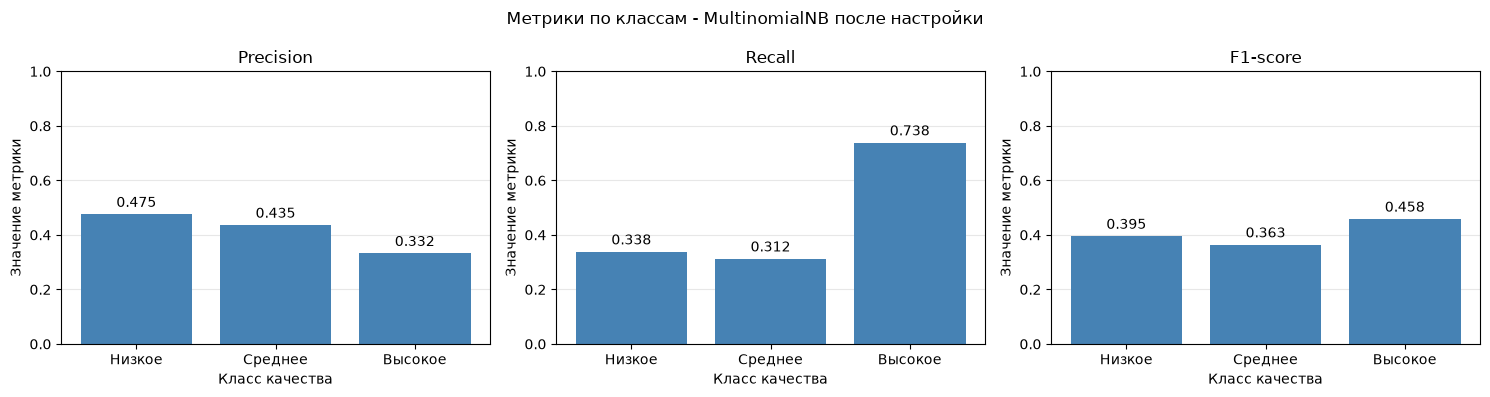

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.475,0.338,0.395
Среднее,0.435,0.312,0.363
Высокое,0.332,0.738,0.458
Макроусреднение,0.414,0.462,0.405


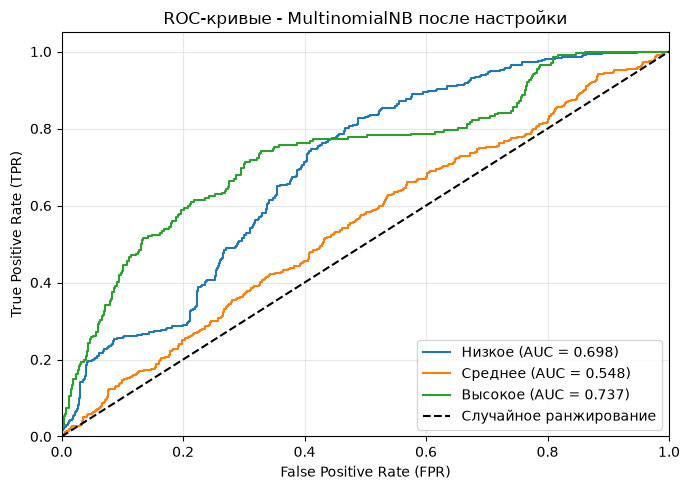

AUC-macro: 0.661

ComplementNB после настройки
Accuracy: 0.446


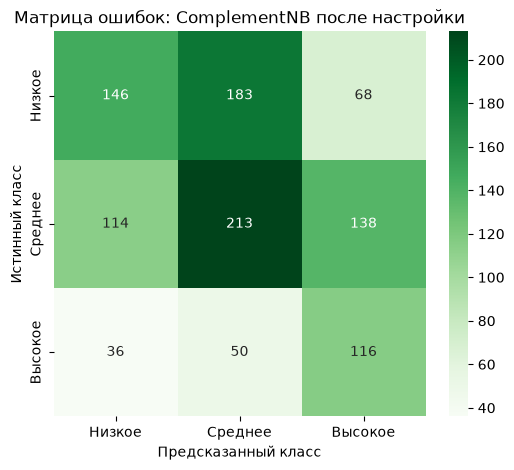

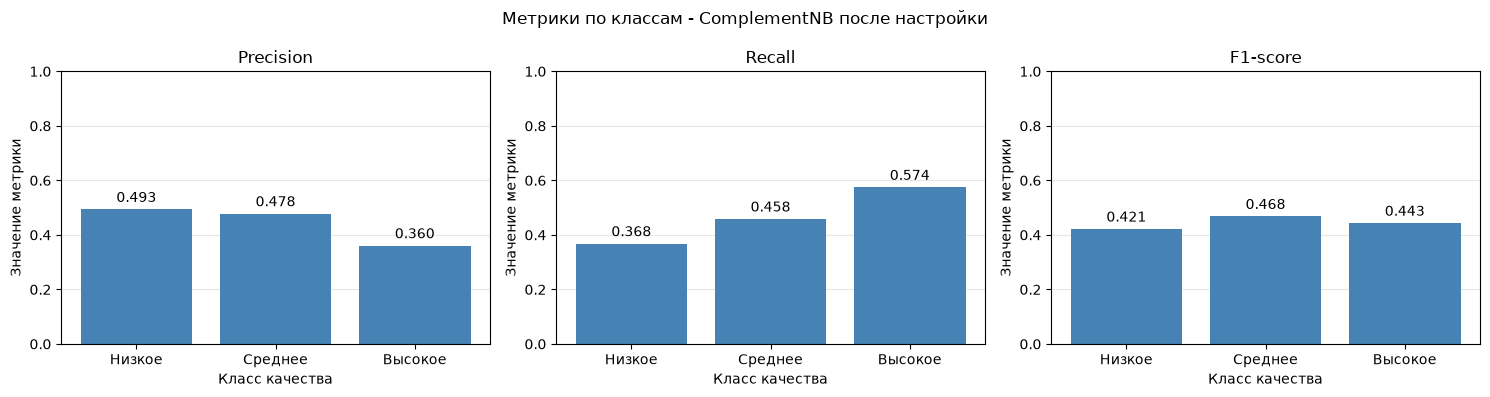

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.493,0.368,0.421
Среднее,0.478,0.458,0.468
Высокое,0.360,0.574,0.443
Макроусреднение,0.444,0.467,0.444


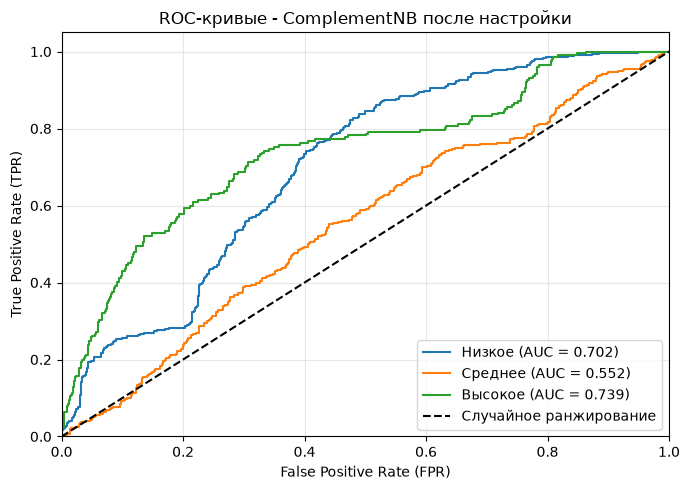

AUC-macro: 0.664

BernoulliNB после настройки
Accuracy: 0.492


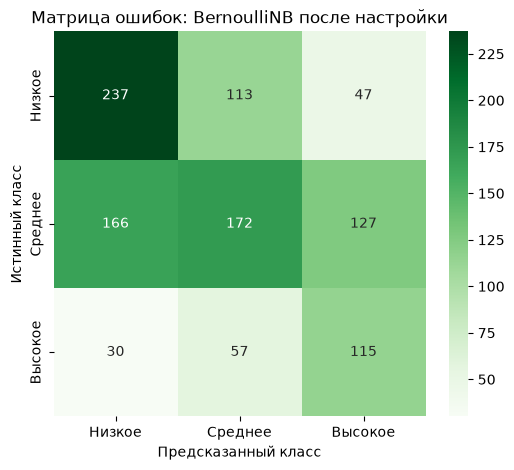

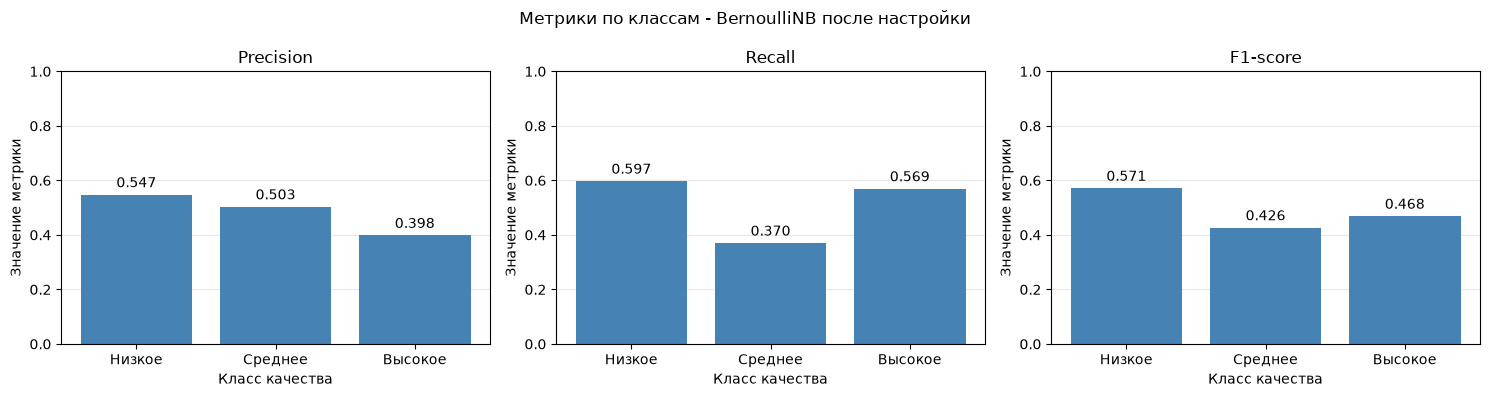

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.547,0.597,0.571
Среднее,0.503,0.370,0.426
Высокое,0.398,0.569,0.468
Макроусреднение,0.483,0.512,0.489


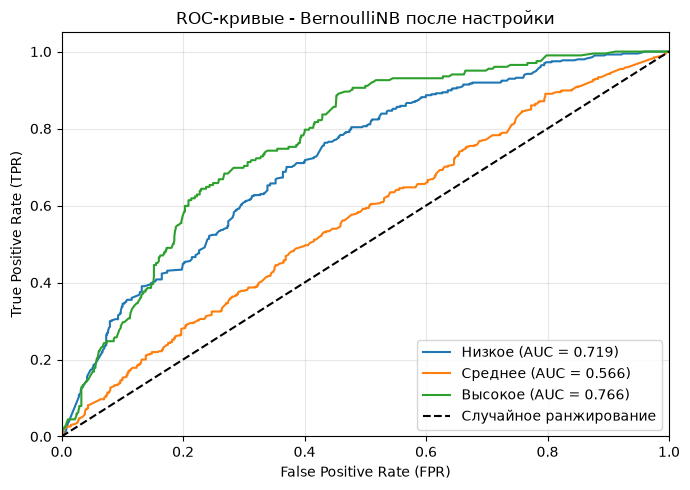

AUC-macro: 0.684

Дерево решений после настройки
Accuracy: 0.574


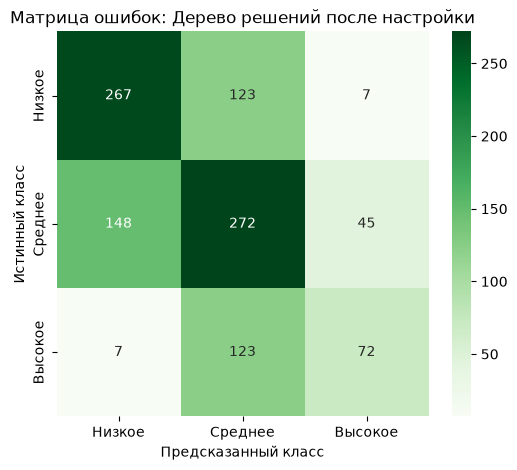

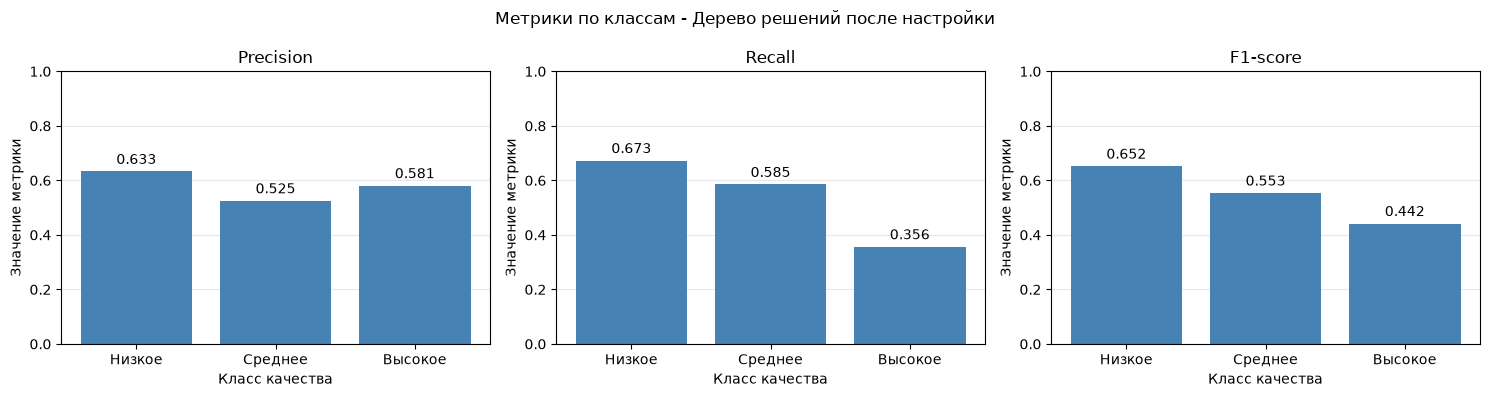

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.633,0.673,0.652
Среднее,0.525,0.585,0.553
Высокое,0.581,0.356,0.442
Макроусреднение,0.579,0.538,0.549


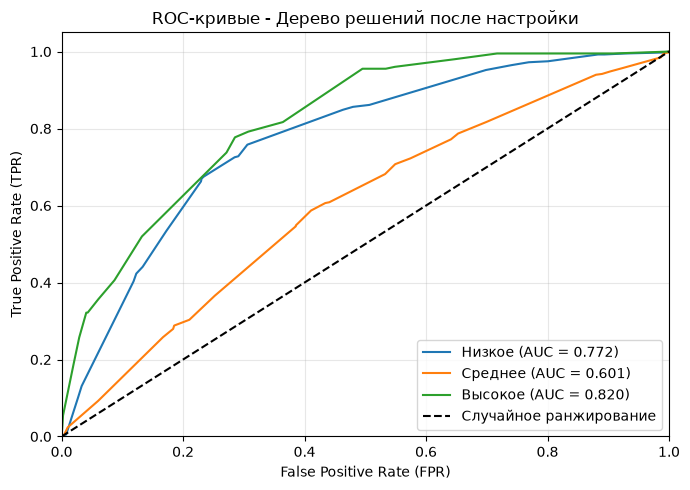

AUC-macro: 0.731

LDA после настройки
Accuracy: 0.563


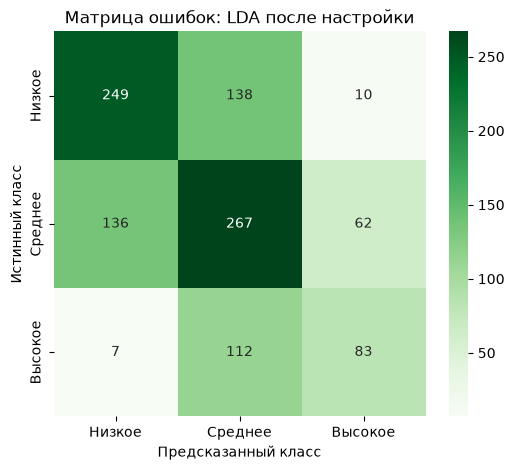

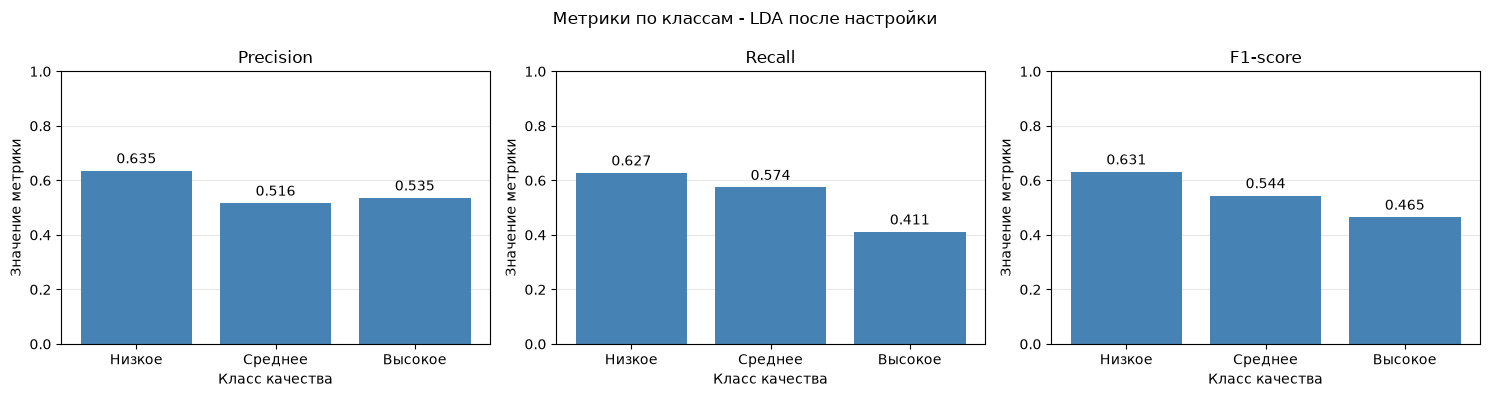

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.635,0.627,0.631
Среднее,0.516,0.574,0.544
Высокое,0.535,0.411,0.465
Макроусреднение,0.562,0.537,0.547


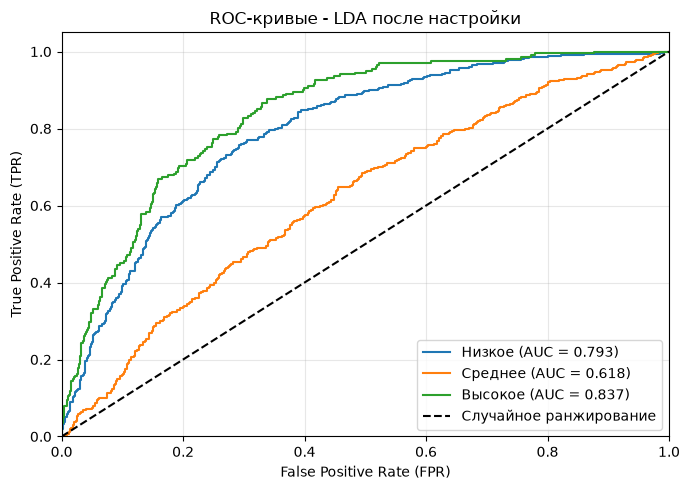

AUC-macro: 0.749

SVM после настройки
Accuracy: 0.587


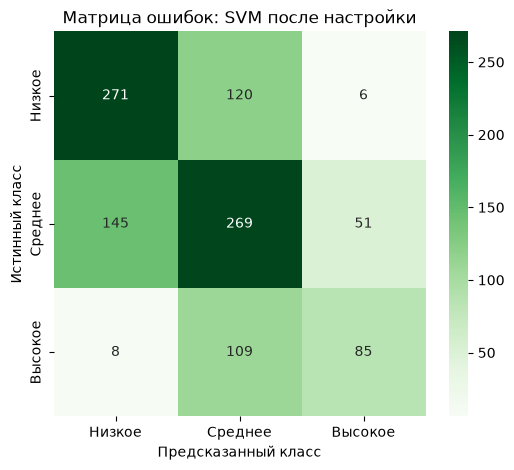

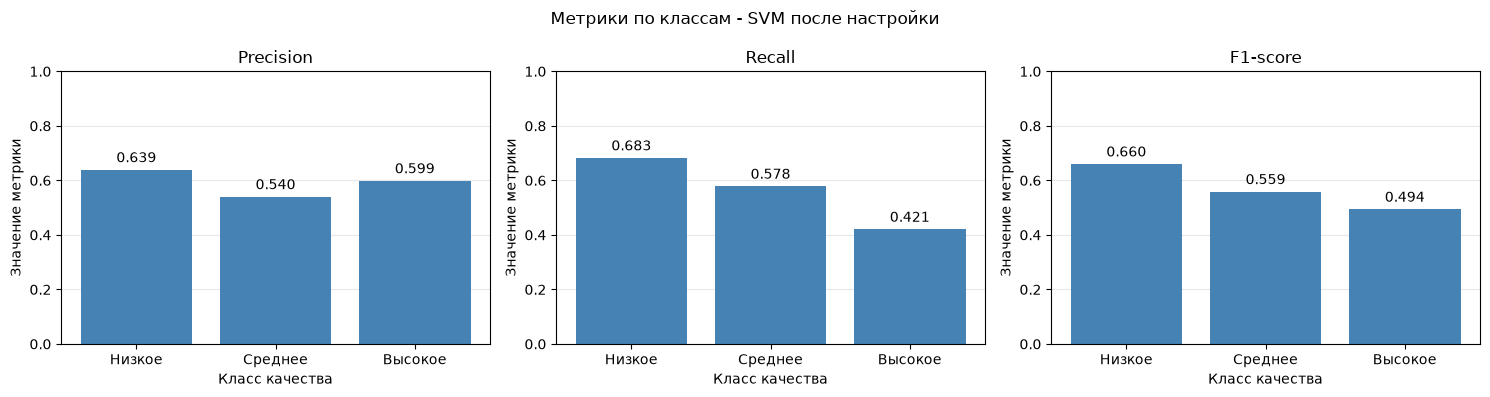

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.639,0.683,0.660
Среднее,0.540,0.578,0.559
Высокое,0.599,0.421,0.494
Макроусреднение,0.593,0.561,0.571


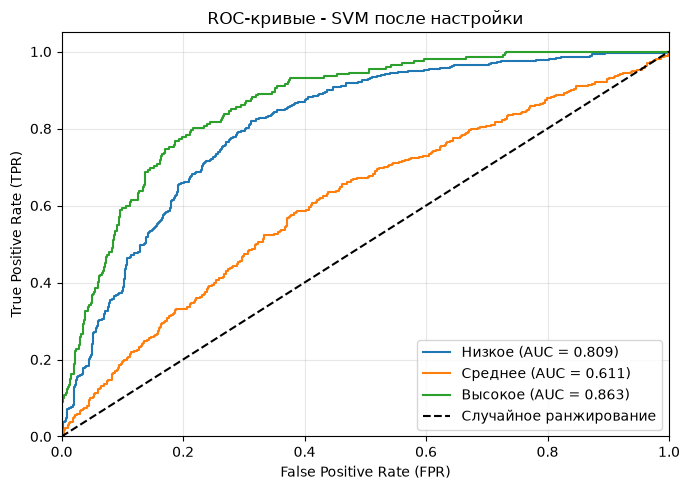

AUC-macro: 0.761

kNN после настройки
Accuracy: 0.578


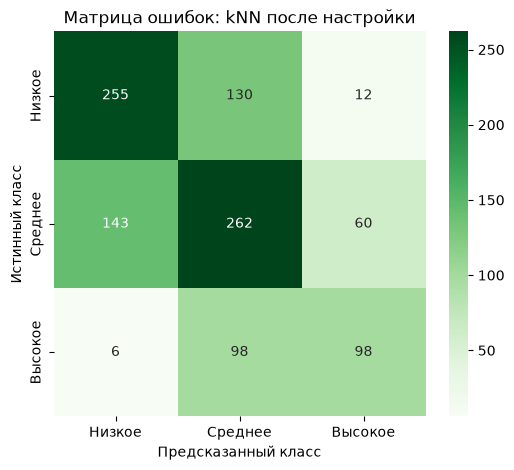

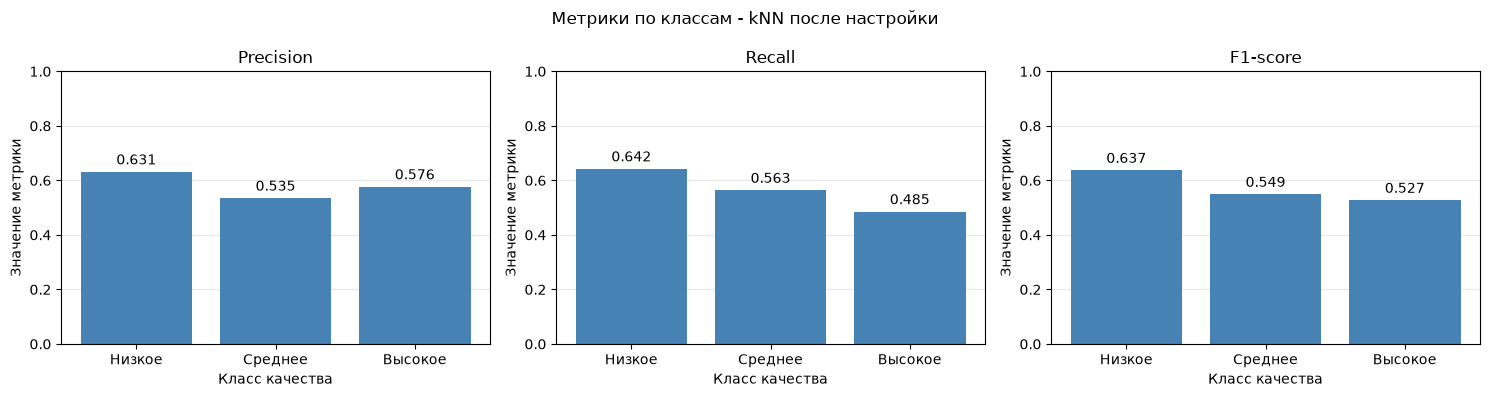

,Precision,Recall,F1-score
Класс качества,,,
Низкое,0.631,0.642,0.637
Среднее,0.535,0.563,0.549
Высокое,0.576,0.485,0.527
Макроусреднение,0.581,0.564,0.571


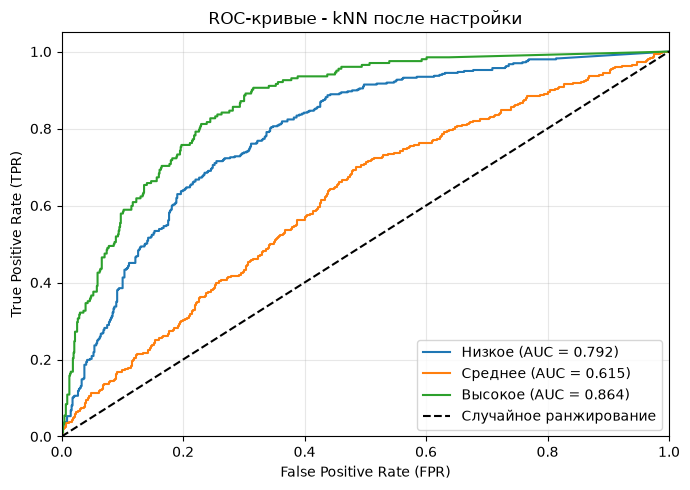

AUC-macro: 0.757


In [49]:
for name, search in searches.items():
    model = search.best_estimator_
    prediction = model.predict(X_test)

    title = f"{name} после настройки"

    print(f"\n{title}")
    print(f"Accuracy: {accuracy_score(Y_test, prediction):.3f}")

    plot_confusion_matrix(Y_test, prediction, title)
    plot_class_metrics(Y_test, prediction, title)
    plot_roc(model, X_test, Y_test, title)

### Результаты классификации после настройки гиперпараметров

Сравнение с предыдущими графиками показывает, что подбор параметров улучшил качество нескольких моделей, однако изменения оказались неодинаковыми для разных классов.

- **GaussianNB:** количество правильно распознанных объектов низкого качества выросло со 184 до 223, среднего - с 200 до 249. Сократилось количество ошибочных предсказаний высокого качества, поэтому Precision этого класса вырос с 0,409 до 0,503. Однако его Recall снизился с 0,644 до 0,475. В целом Accuracy вырос с 0,483 до 0,534, F1-macro - с 0,487 до 0,528, AUC-macro - с 0,690 до 0,711.

- **MultinomialNB:** модель начала предсказывать высокое качество и правильно обнаружила 149 из 202 объектов этого класса, тогда как до настройки не обнаруживала ни одного. F1-macro вырос с 0,307 до 0,405. При этом распознавание среднего качества ухудшилось, а Accuracy снизился с 0,449 до 0,402. Следовательно, улучшение связано с распознаванием ранее пропускаемого класса, а не с увеличением общего количества правильных ответов.

- **Дерево решений:** количество правильных ответов для низкого качества выросло с 235 до 267, для среднего - с 232 до 272. Accuracy увеличился с 0,525 до 0,574, F1-macro - с 0,515 до 0,549. ROC-кривые показывают улучшение ранжирования всех трёх классов: AUC-macro вырос с 0,631 до 0,731. Однако Recall высокого качества снизился с 0,455 до 0,356.

- **SVM:** количество правильно обнаруженных объектов высокого качества выросло с 70 до 85. Recall этого класса увеличился с 0,347 до 0,421, а F1-score - с 0,453 до 0,494. Общий F1-macro вырос с 0,563 до 0,571, хотя Accuracy и AUC-macro немного снизились.

- **kNN:** F1-score вырос для всех трёх классов. Количество правильно обнаруженных объектов высокого качества увеличилось с 88 до 98, а число ошибок, когда высокое качество принималось за низкое, сократилось с 20 до 6. Accuracy вырос с 0,564 до 0,578, F1-macro - с 0,554 до 0,571, AUC-macro - с 0,725 до 0,757.

- **LDA и ComplementNB:** результаты не изменились, поскольку подобранные параметры совпали с исходными. У **BernoulliNB** изменения незначительны и не привели к улучшению общего F1-macro.

Настройка повысила F1-macro у пяти классификаторов, но не обеспечила улучшение каждой метрики и каждого класса. После настройки SVM и kNN показали близкий общий F1-macro - около 0,571. При этом kNN лучше распознаёт высокое качество по F1-score: 0,527 против 0,494 у SVM.